# Eksperimen Forecasting Penggunaan 6 Bahan Baku (H+1 dan H+2)
Alur: **konfigurasi → baca data (format lebar Excel) → preprocessing & cleaning → EDA → rekayasa fitur (X1–X8) → operasionalisasi variabel → target Y → split waktu → penskalaan → pemodelan → evaluasi → prediksi besok & lusa → SPK**

Sumber data: `5. SO JA GARBIS MEI 2026.xlsx` (sheet `Data Stok&Order` untuk penggunaan & stok, `HPP Harian` untuk omzet dan target omzet, `List Suplier` untuk pemasok).

In [ ]:
# Jalankan sekali jika library belum terpasang
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl xgboost

## 0. Import library

In [7]:
import os
import re
import glob
import datetime
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.base import clone

try:
    from xgboost import XGBRegressor
    ADA_XGB = True
except Exception:
    ADA_XGB = False
    print("XGBoost tidak terpasang -> dilewati (tidak masalah, eksperimen tetap jalan).")

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore", message="Data Validation extension")
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

## 1. Konfigurasi
Ubah nama file dan asumsi di sini. **Lead time** dan **pemetaan bahan** masih asumsi, ganti jika sudah ada data pastinya.

In [ ]:
# ---------- File sumber ----------
FILE_DATASET = "5. SO JA GARBIS MEI 2026.xlsx"
SHEET_STOK = "Data Stok&Order"    # sheet penggunaan & stok harian (format lebar: 1 blok kolom per tanggal)
SHEET_OMZET = "HPP Harian"        # sheet omzet harian + baris TARGET (target bulanan)
SHEET_SUPPLIER = "List Suplier"   # sheet pemasok
DEMO_MODE = False                 # True = data simulasi HANYA untuk mencoba alur kode (bukan data asli)

# ---------- Struktur sheet "Data Stok&Order" (posisi kolom 0-based, sesuai file Mei 2026) ----------
BARIS_TANGGAL = 0        # baris yang memuat tanggal tiap blok
KOLOM_NAMA = 1           # kolom nama bahan
OFFSET_STOK = 4          # kolom 'SO Gudang' = kolom tanggal + 4
OFFSET_PENGGUNAAN = 5    # kolom 'Penggunaan' = kolom tanggal + 5

# ---------- Objek penelitian ----------
BAHAN_BAKU = ["Ayam", "Telur", "Beras", "Minyak Goreng", "Cabai", "Teh Tarik"]

# Pemetaan nama di sumber (huruf kecil) -> nama baku. Sesuaikan jika nama di datamu berbeda.
# Cabai = cabe rawit hijau + cabe rawit merah (dijumlahkan). Teh Tarik = Teh A (satuan gram; Teh B satuannya bag sehingga tidak dicampur).
MAPPING_BAHAN = {
    "ayam cut 10": "Ayam",
    "telur ayam": "Telur",
    "beras c": "Beras",
    "minyak goreng": "Minyak Goreng",
    "cabe rawit hijau": "Cabai", "cabe rawit merah": "Cabai",
    "teh a": "Teh Tarik",
}

# X8: lead time pemasok (hari). Sheet 'List Suplier' hanya berisi nama pemasok (Central Kitchen Jaco / BLISAYUR.27),
# tanpa angka lead time. ASUMSI: order malam -> barang tiba pagi berikutnya = 1 hari.
LEAD_TIME_HARI = {b: 1 for b in BAHAN_BAKU}

# ---------- Parameter eksperimen ----------
HORIZONS = [1, 2]            # 1 = besok, 2 = lusa (maksimal 7)
WINDOW = 7                   # jendela rata-rata & simpangan baku bergulir
TRAIN_FRAC = 0.7             # porsi tanggal target paling awal untuk latih; sisanya uji
MODE_PEMODELAN = ["gabungan", "per_bahan"]   # satu model utk 6 bahan, dan satu model per bahan
BATAS_INTERPOLASI = 2        # celah data kosong maksimum (hari) yang diisi interpolasi
HAPUS_Y_IMPUTASI = True      # baris yang targetnya hasil imputasi tidak dipakai latih/uji
RANDOM_STATE = 42
FOLDER_OUTPUT = "output_eksperimen"
os.makedirs(FOLDER_OUTPUT, exist_ok=True)

# Tanggal merah & cuti bersama 2026. Mei 2026 sudah dicek; bulan lain belum terverifikasi.
TANGGAL_MERAH = pd.to_datetime([
    "2026-01-01", "2026-01-16", "2026-02-16", "2026-02-17", "2026-03-18", "2026-03-19",
    "2026-03-20", "2026-03-21", "2026-03-22", "2026-03-23", "2026-03-24", "2026-04-03",
    "2026-04-05", "2026-05-01", "2026-05-14", "2026-05-15", "2026-05-27", "2026-05-28",
    "2026-05-31", "2026-06-01", "2026-06-16", "2026-08-17", "2026-08-25", "2026-12-24",
    "2026-12-25",
])

assert all(1 <= h <= 7 for h in HORIZONS), "Horizon harus 1..7 agar Lag-7 tersedia saat prediksi."

## 2. Membaca data
File Excel berformat **lebar**: tiap tanggal punya blok 8 kolom (Brg msk, Sisa Bag, Open, Waste, SO Gudang, Penggunaan, Total harga, Order).
Fungsi di bawah mengubahnya menjadi tabel **panjang** (1 baris = 1 bahan × 1 tanggal), lalu membaca omzet harian dan target omzet dari sheet `HPP Harian`.

In [9]:
def cari_file(nama):
    """Cari file Excel: nama persis, atau yang namanya sama setelah simbol dibuang, atau yang memuat 'garbis'."""
    if os.path.exists(nama):
        return nama
    bersih = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
    semua = glob.glob("*.xlsx")
    cocok = [f for f in semua if bersih(f) == bersih(nama)] or [f for f in semua if "garbis" in f.lower()]
    if not cocok:
        raise FileNotFoundError(f"File '{nama}' tidak ditemukan di folder {os.getcwd()}. File .xlsx yang ada: {semua}")
    return cocok[0]


def cek_sheet(path, sheet):
    semua = pd.ExcelFile(path).sheet_names
    if sheet not in semua:
        raise ValueError(f"Sheet '{sheet}' tidak ada. Sheet tersedia: {semua}")
    return sheet


def ke_angka(seri):
    return pd.to_numeric(seri, errors="coerce")


def penanda_libur(tanggal):
    """1 jika tanggal merah/cuti bersama ATAU bagian dari libur panjang
    (rangkaian >= 3 hari libur berurutan, termasuk akhir pekan, yang memuat minimal satu tanggal merah)."""
    tanggal = pd.DatetimeIndex(tanggal)
    kal = pd.date_range(tanggal.min() - pd.Timedelta(days=14), tanggal.max() + pd.Timedelta(days=14), freq="D")
    merah = pd.Series(kal.isin(TANGGAL_MERAH), index=kal)
    libur = merah | pd.Series(kal.dayofweek >= 5, index=kal)
    blok = (libur != libur.shift()).cumsum()
    panjang_blok = libur.groupby(blok).transform("sum")
    ada_merah = merah.groupby(blok).transform("any")
    flag = merah | (libur & (panjang_blok >= 3) & ada_merah)
    return flag.reindex(tanggal).astype(int).values

In [10]:
def buat_data_demo():
    """Data simulasi HANYA untuk menguji alur kode. Jangan dipakai untuk kesimpulan penelitian."""
    rng = np.random.default_rng(RANDOM_STATE)
    tgl = pd.date_range("2026-05-01", "2026-05-31", freq="D")
    skala = {"Ayam": 60, "Telur": 40, "Beras": 24, "Minyak Goreng": 12, "Cabai": 5, "Teh Tarik": 30}
    baris = []
    for b, s in skala.items():
        stok = s * 4
        for t in tgl:
            pola = 1.25 if t.dayofweek >= 5 else 1.0
            guna = max(0.0, rng.normal(s * pola, s * 0.12))
            stok = stok - guna + (s * 2 if rng.random() < 0.3 else 0)
            baris.append([t, b, round(guna, 2), round(stok, 2)])
    pg = pd.DataFrame(baris, columns=["Tanggal", "Nama Bahan", "Penggunaan", "Stok"])
    pg.loc[(pg["Nama Bahan"] == "Minyak Goreng") & (pg["Tanggal"] == "2026-05-18"), "Penggunaan"] = -1176  # kasus ganjil
    pg = pg.drop(pg[(pg["Nama Bahan"] == "Telur") & (pg["Tanggal"] == "2026-05-10")].index)                # data hilang
    pg["Nama Bahan"] = pg["Nama Bahan"].str.lower()
    om = pd.DataFrame({"Tanggal": tgl, "Omzet": rng.normal(15e6, 3e6, len(tgl)).round(-3), "Target Bulanan": 267523939.0})
    return pg, om


def muat_penggunaan():
    """Ubah sheet lebar 'Data Stok&Order' menjadi tabel panjang: Tanggal, Nama Bahan, Penggunaan, Stok."""
    if DEMO_MODE:
        return buat_data_demo()[0]
    path = cari_file(FILE_DATASET)
    sheet = cek_sheet(path, SHEET_STOK)
    mentah = pd.read_excel(path, sheet_name=sheet, header=None)
    kolom_tgl = [(j, pd.Timestamp(v).normalize()) for j, v in mentah.iloc[BARIS_TANGGAL].items()
                 if isinstance(v, (pd.Timestamp, datetime.datetime))]
    if not kolom_tgl:
        raise ValueError(f"Tidak ada tanggal pada baris {BARIS_TANGGAL} sheet '{sheet}'. Periksa BARIS_TANGGAL.")
    nama = mentah[KOLOM_NAMA].map(lambda x: str(x).strip().lower())
    baris_pakai = nama[nama.isin(MAPPING_BAHAN.keys())]
    if baris_pakai.empty:
        raise ValueError("Tidak ada nama bahan di sheet yang cocok dengan MAPPING_BAHAN. Periksa KOLOM_NAMA / MAPPING_BAHAN.")
    out = []
    for i, nm in baris_pakai.items():
        for j, t in kolom_tgl:
            out.append([t, nm, mentah.iat[i, j + OFFSET_PENGGUNAAN], mentah.iat[i, j + OFFSET_STOK]])
    return pd.DataFrame(out, columns=["Tanggal", "Nama Bahan", "Penggunaan", "Stok"])


def muat_omzet():
    """Omzet harian dari blok tabel pertama sheet 'HPP Harian' + target omzet bulanan dari baris 'TARGET'."""
    if DEMO_MODE:
        return buat_data_demo()[1]
    path = cari_file(FILE_DATASET)
    sheet = cek_sheet(path, SHEET_OMZET)
    mentah = pd.read_excel(path, sheet_name=sheet, header=None)
    # cari baris header (memuat 'tgl' dan 'omzet')
    idx_head = None
    for i in range(min(30, len(mentah))):
        isi = [str(v).strip().lower() for v in mentah.iloc[i].tolist() if pd.notna(v)]
        if "tgl" in isi and "omzet" in isi:
            idx_head = i
            break
    if idx_head is None:
        raise ValueError(f"Baris header 'tgl' & 'OMZET' tidak ditemukan di sheet '{sheet}'.")
    head = [str(v).strip().lower() if pd.notna(v) else f"k{j}" for j, v in enumerate(mentah.iloc[idx_head].tolist())]
    c_tgl, c_omz = head.index("tgl"), head.index("omzet")
    harian, target_bulanan, mulai = [], np.nan, False
    for i in range(idx_head + 1, len(mentah)):          # hanya blok tabel pertama (tabel berikutnya adalah duplikat/tabel lain)
        v, om = mentah.iat[i, c_tgl], mentah.iat[i, c_omz]
        if isinstance(v, (pd.Timestamp, datetime.datetime)):
            mulai = True
            harian.append([pd.Timestamp(v).normalize(), om])
        elif mulai and pd.notna(v):
            if str(v).strip().lower() == "target":
                target_bulanan = pd.to_numeric(om, errors="coerce")
            if str(v).strip().lower() == "gap":
                break
    om = pd.DataFrame(harian, columns=["Tanggal", "Omzet"])
    om["Target Bulanan"] = target_bulanan
    return om


raw_guna = muat_penggunaan()
raw_omzet = muat_omzet()
print("Data penggunaan mentah:", raw_guna.shape, "| kolom:", list(raw_guna.columns))
print("Data omzet mentah     :", raw_omzet.shape, "| kolom:", list(raw_omzet.columns))
display(raw_guna.head())
display(raw_omzet.head())

Data penggunaan mentah: (217, 4) | kolom: ['Tanggal', 'Nama Bahan', 'Penggunaan', 'Stok']
Data omzet mentah     : (31, 3) | kolom: ['Tanggal', 'Omzet', 'Target Bulanan']


,Tanggal,Nama Bahan,Penggunaan,Stok
0,2026-05-01,teh a,358,3279
1,2026-05-02,teh a,562,2717
2,2026-05-03,teh a,694,2023
3,2026-05-04,teh a,230,1793
4,2026-05-05,teh a,282,1511


,Tanggal,Omzet,Target Bulanan
0,2026-05-01,15915000,267523939
1,2026-05-02,16605000,267523939
2,2026-05-03,17602000,267523939
3,2026-05-04,7229000,267523939
4,2026-05-05,6655000,267523939


## 3. Preprocessing dan data cleaning
Langkah: standarisasi kolom → pemetaan 6 bahan → parsing tanggal → gabung duplikat → kalender lengkap → tangani nilai negatif / kosong → tandai outlier.

In [11]:
# ---- 3.1 Standarisasi kolom ----
df = pd.DataFrame({
    "tanggal": pd.to_datetime(raw_guna["Tanggal"], errors="coerce").dt.normalize(),
    "nama_asli": raw_guna["Nama Bahan"].astype(str).str.strip(),
    "penggunaan": ke_angka(raw_guna["Penggunaan"]),
    "stok": ke_angka(raw_guna["Stok"]),
})
n_awal = len(df)
tgl_gagal = df["tanggal"].isna().sum()
non_angka = (raw_guna["Penggunaan"].notna() & df["penggunaan"].isna()).sum()
df = df.dropna(subset=["tanggal"]).copy()
print(f"Baris awal: {n_awal} | tanggal tidak terbaca (dibuang): {tgl_gagal} | nilai penggunaan non-angka (jadi kosong): {non_angka}")

# ---- 3.2 Pemetaan 6 bahan baku ----
df["bahan_baku"] = df["nama_asli"].str.lower().map(MAPPING_BAHAN)
df = df.dropna(subset=["bahan_baku"]).copy()
print("\nPemetaan nama sumber -> bahan baku penelitian (periksa apakah sudah sesuai):")
display(df.groupby(["bahan_baku", "nama_asli"]).size().rename("jumlah_baris").reset_index())
hilang = [b for b in BAHAN_BAKU if b not in df["bahan_baku"].unique()]
if hilang:
    raise ValueError(f"Bahan berikut tidak ditemukan setelah pemetaan: {hilang}. Perbaiki MAPPING_BAHAN.")

# ---- 3.3 Duplikat tanggal-bahan (mis. dua jenis cabai) dijumlahkan ----
n_dup = df.duplicated(["tanggal", "bahan_baku"]).sum()
df = (df.groupby(["tanggal", "bahan_baku"], as_index=False)
        .agg(penggunaan=("penggunaan", lambda s: s.sum(min_count=1)),
             stok=("stok", lambda s: s.sum(min_count=1))))
print(f"Baris duplikat tanggal-bahan yang digabung (dijumlahkan): {n_dup}")

# ---- 3.4 Kalender lengkap per bahan ----
kalender = pd.date_range(df["tanggal"].min(), df["tanggal"].max(), freq="D")
idx = pd.MultiIndex.from_product([kalender, BAHAN_BAKU], names=["tanggal", "bahan_baku"])
df = df.set_index(["tanggal", "bahan_baku"]).reindex(idx).reset_index()
print("Rentang tanggal:", kalender.min().date(), "s.d.", kalender.max().date(), "|", len(kalender), "hari")
print("Nilai penggunaan kosong per bahan (sebelum cleaning):")
display(df.groupby("bahan_baku")["penggunaan"].apply(lambda s: s.isna().sum()).rename("kosong"))

# ---- 3.5 Nilai tidak valid: negatif -> kosong, lalu isi celah pendek dengan interpolasi ----
df["penggunaan_asli"] = df["penggunaan"]
df["negatif"] = df["penggunaan"] < 0
print("\nNilai penggunaan negatif (dianggap tidak valid -> kosong):")
display(df.loc[df["negatif"], ["tanggal", "bahan_baku", "penggunaan"]])
df.loc[df["negatif"], "penggunaan"] = np.nan

df = df.sort_values(["bahan_baku", "tanggal"]).reset_index(drop=True)
kosong_sebelum = df["penggunaan"].isna()
df["penggunaan"] = (df.groupby("bahan_baku")["penggunaan"]
                      .transform(lambda s: s.interpolate(method="linear", limit=BATAS_INTERPOLASI, limit_area="inside")))
df["diimputasi"] = (kosong_sebelum & df["penggunaan"].notna()).astype(bool)
df["stok"] = df.groupby("bahan_baku")["stok"].transform(
    lambda s: s.interpolate(method="linear", limit=BATAS_INTERPOLASI, limit_area="inside"))
print(f"Nilai yang diisi interpolasi: {int(df['diimputasi'].sum())} | masih kosong: {int(df['penggunaan'].isna().sum())}")

# ---- 3.6 Penanda outlier (hanya ditandai, TIDAK dihapus) ----
def tandai_outlier(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).fillna(False)

df["outlier_iqr"] = df.groupby("bahan_baku")["penggunaan"].transform(tandai_outlier).astype(bool)
print("\nJumlah outlier (IQR) per bahan:")
display(df.groupby("bahan_baku")["outlier_iqr"].sum().rename("outlier"))

df_bersih = df[["tanggal", "bahan_baku", "penggunaan", "stok", "penggunaan_asli", "diimputasi", "outlier_iqr"]].copy()

# ---- 3.7 Data omzet + target omzet harian ----
df_omzet = pd.DataFrame({
    "tanggal": pd.to_datetime(raw_omzet["Tanggal"], errors="coerce").dt.normalize(),
    "omzet": ke_angka(raw_omzet["Omzet"]),
    "target_bulanan": ke_angka(raw_omzet["Target Bulanan"]),
}).dropna(subset=["tanggal"])
df_omzet = (df_omzet.groupby("tanggal", as_index=False)
                    .agg(omzet=("omzet", lambda s: s.sum(min_count=1)),
                         target_bulanan=("target_bulanan", "max")))
df_omzet = df_omzet.set_index("tanggal").reindex(kalender)
df_omzet.index.name = "tanggal"
df_omzet["omzet"] = df_omzet["omzet"].interpolate(limit=BATAS_INTERPOLASI, limit_area="inside")
df_omzet["target_bulanan"] = df_omzet["target_bulanan"].ffill().bfill()
# Target omzet HARIAN = target bulanan dibagi jumlah hari pada bulan tersebut (target di file hanya tersedia per bulan)
df_omzet["target_omzet"] = df_omzet["target_bulanan"] / df_omzet.index.days_in_month
df_omzet = df_omzet.reset_index()
print("Omzet kosong setelah cleaning:", int(df_omzet["omzet"].isna().sum()), "dari", len(df_omzet), "hari")
print("Target omzet bulanan:", df_omzet["target_bulanan"].iloc[0], "| target harian:", round(df_omzet["target_omzet"].iloc[0]))

print("\nRingkasan data bersih:")
display(df_bersih.describe(include="all").T)

Baris awal: 217 | tanggal tidak terbaca (dibuang): 0 | nilai penggunaan non-angka (jadi kosong): 0

Pemetaan nama sumber -> bahan baku penelitian (periksa apakah sudah sesuai):


,bahan_baku,nama_asli,jumlah_baris
0,Ayam,ayam cut 10,31
1,Beras,beras c,31
2,Cabai,cabe rawit hijau,31
3,Cabai,cabe rawit merah,31
4,Minyak Goreng,minyak goreng,31
5,Teh Tarik,teh a,31
6,Telur,telur ayam,31


Baris duplikat tanggal-bahan yang digabung (dijumlahkan): 31
Rentang tanggal: 2026-05-01 s.d. 2026-05-31 | 31 hari
Nilai penggunaan kosong per bahan (sebelum cleaning):


bahan_baku
Ayam             0
Beras            0
Cabai            0
Minyak Goreng    0
Teh Tarik        0
Telur            0
Name: kosong, dtype: int64


Nilai penggunaan negatif (dianggap tidak valid -> kosong):


,tanggal,bahan_baku,penggunaan
105,2026-05-18,Minyak Goreng,-1176


Nilai yang diisi interpolasi: 1 | masih kosong: 0

Jumlah outlier (IQR) per bahan:


bahan_baku
Ayam             2
Beras            0
Cabai            3
Minyak Goreng    1
Teh Tarik        0
Telur            0
Name: outlier, dtype: int64

Omzet kosong setelah cleaning: 0 dari 31 hari
Target omzet bulanan: 267523939 | target harian: 8629804

Ringkasan data bersih:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
tanggal,186,NaN,NaN,NaN,2026-05-16 00:00:00,2026-05-01 00:00:00,2026-05-08 00:00:00,2026-05-16 00:00:00,2026-05-24 00:00:00,2026-05-31 00:00:00,NaN
bahan_baku,186,6,Ayam,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
penggunaan,186.0,NaN,NaN,NaN,4539.620968,0.0,117.25,242.0,4240.25,36384.0,8672.441164
stok,186.0,NaN,NaN,NaN,17034.849462,0.0,110.0,1026.0,37408.0,86690.0,24804.104423
penggunaan_asli,186.0,NaN,NaN,NaN,4512.370968,-1176.0,115.5,235.5,4240.25,36384.0,8682.442692
diimputasi,186,2,False,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
outlier_iqr,186,2,False,180,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Exploratory Data Analysis (EDA)

Statistik penggunaan per bahan baku:


,count,mean,std,min,median,max,cv(std/mean),persen_nol
bahan_baku,,,,,,,,
Ayam,31,38.71,25.66,0.0,40.0,120.0,0.66,12.9
Beras,31,21830.00,8550.13,8054.0,20626.0,36384.0,0.39,0.0
Cabai,31,221.03,130.12,18.0,197.0,622.0,0.59,0.0
Minyak Goreng,31,4652.27,1850.10,2064.0,4285.0,10378.0,0.40,0.0
Teh Tarik,31,339.87,172.48,120.0,280.0,694.0,0.51,0.0
Telur,31,155.84,52.58,69.0,156.0,275.0,0.34,0.0


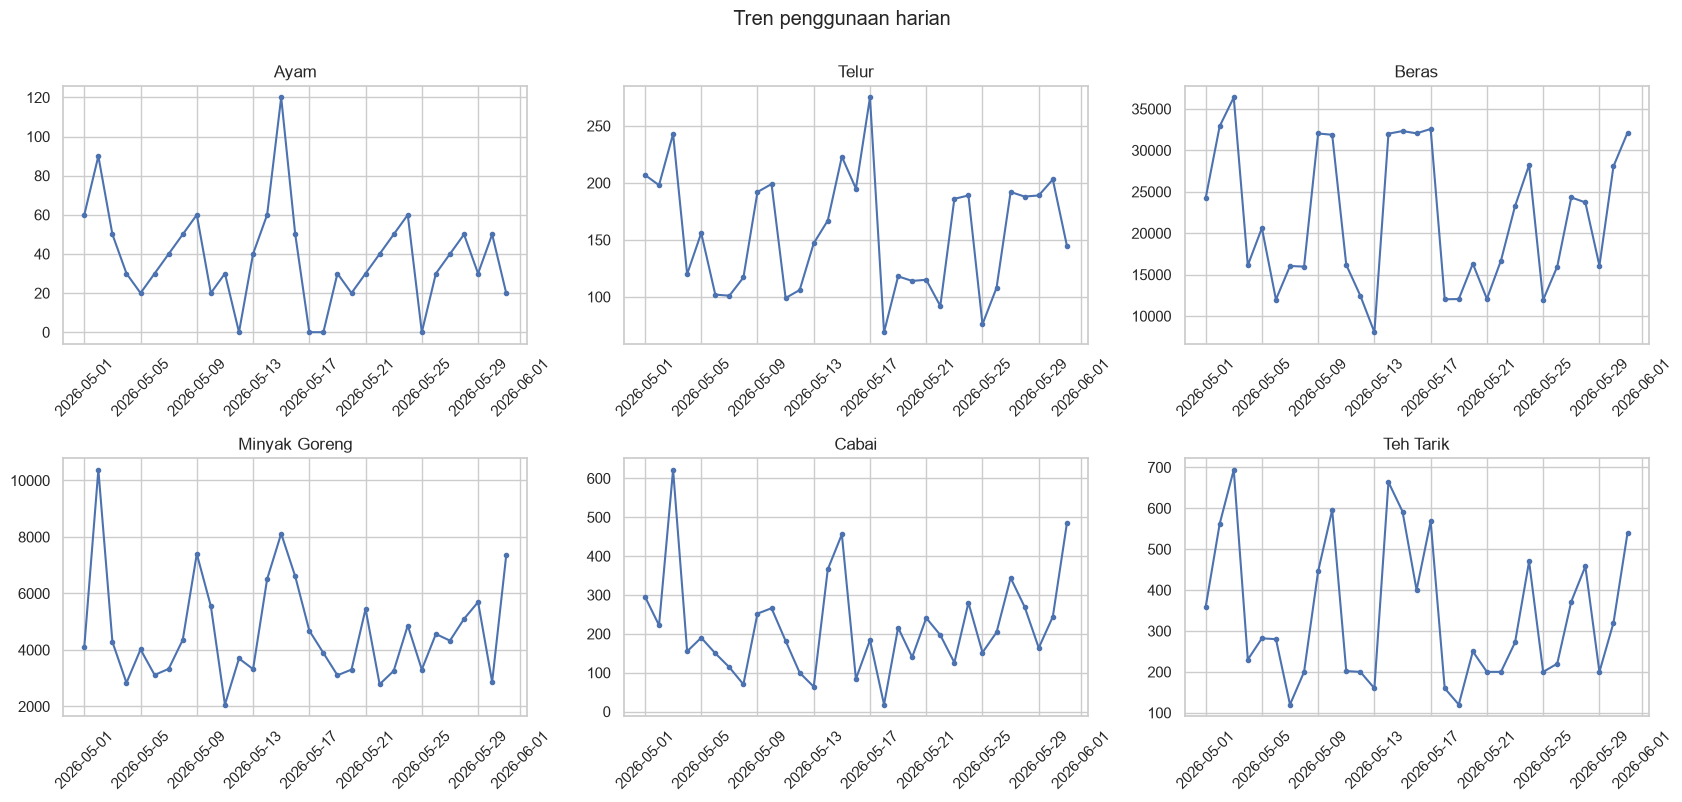

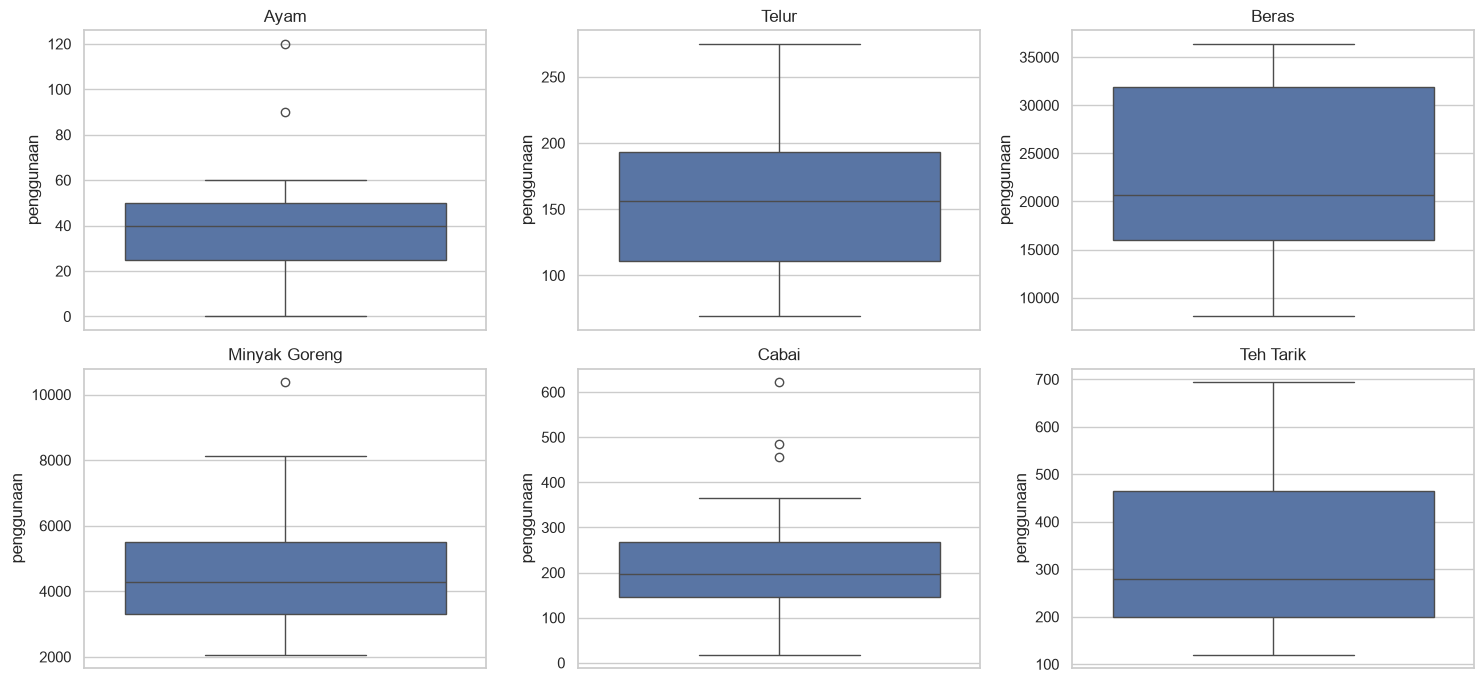

Rata-rata penggunaan hari kerja vs akhir pekan:


jenis_hari,Akhir pekan,Hari kerja
bahan_baku,,
Ayam,45.0,35.71
Beras,30952.8,17485.81
Cabai,276.4,194.67
Minyak Goreng,5723.0,4142.40
Teh Tarik,486.8,269.90
Telur,202.5,133.62


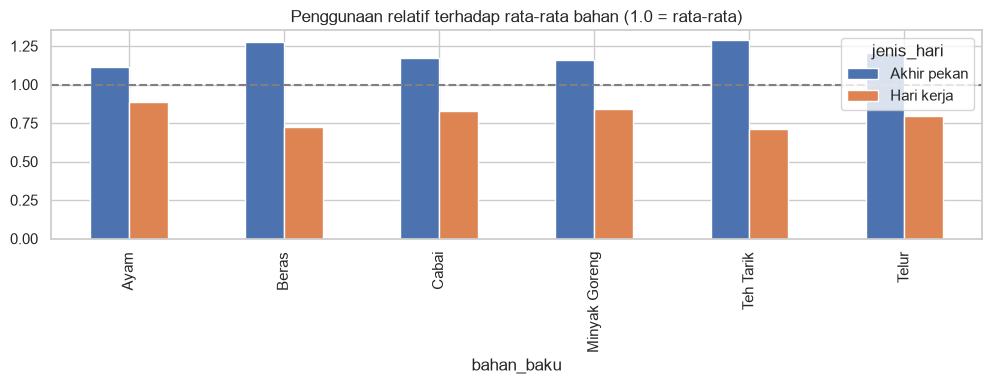

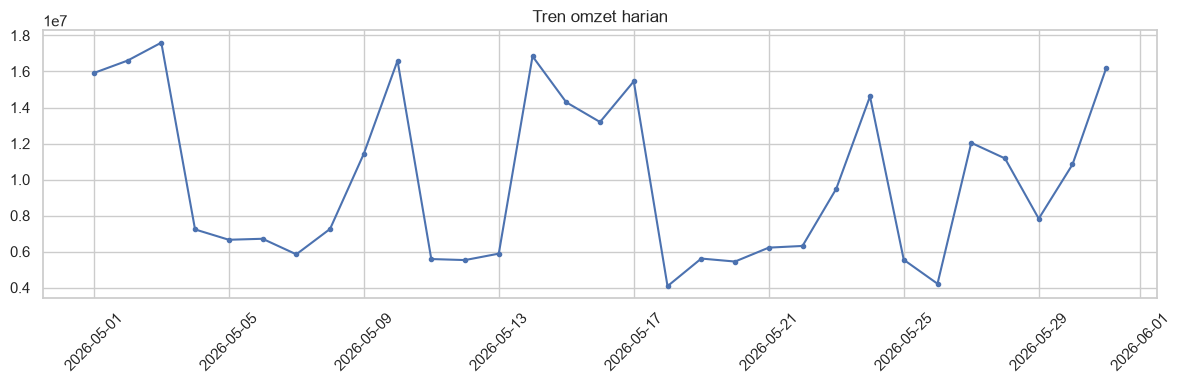

Korelasi penggunaan vs omzet (hari yang sama):


,korelasi
Ayam,0.480
Telur,0.817
Beras,0.921
Minyak Goreng,0.622
Cabai,0.693
Teh Tarik,0.930


In [12]:
# 4.1 Statistik deskriptif per bahan
ringkas = (df_bersih.groupby("bahan_baku")["penggunaan"]
           .agg(["count", "mean", "std", "min", "median", "max"]).round(2))
ringkas["cv(std/mean)"] = (ringkas["std"] / ringkas["mean"]).round(2)
ringkas["persen_nol"] = df_bersih.groupby("bahan_baku")["penggunaan"].apply(lambda s: (s == 0).mean() * 100).round(1)
print("Statistik penggunaan per bahan baku:")
display(ringkas)

# 4.2 Tren penggunaan harian
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, b in zip(axes.ravel(), BAHAN_BAKU):
    g = df_bersih[df_bersih["bahan_baku"] == b]
    ax.plot(g["tanggal"], g["penggunaan"], marker="o", ms=3)
    ax.set_title(b); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Tren penggunaan harian", y=1.0)
plt.tight_layout(); plt.savefig(f"{FOLDER_OUTPUT}/eda_tren_penggunaan.png", dpi=130); plt.show()

# 4.3 Sebaran (boxplot) per bahan
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, b in zip(axes.ravel(), BAHAN_BAKU):
    sns.boxplot(y=df_bersih.loc[df_bersih["bahan_baku"] == b, "penggunaan"].dropna(), ax=ax)
    ax.set_title(b); ax.set_ylabel("penggunaan")
plt.tight_layout(); plt.savefig(f"{FOLDER_OUTPUT}/eda_boxplot.png", dpi=130); plt.show()

# 4.4 Pola hari kerja vs akhir pekan
tmp = df_bersih.copy()
tmp["jenis_hari"] = np.where(tmp["tanggal"].dt.dayofweek < 5, "Hari kerja", "Akhir pekan")
pola = tmp.groupby(["bahan_baku", "jenis_hari"])["penggunaan"].mean().unstack()
print("Rata-rata penggunaan hari kerja vs akhir pekan:")
display(pola.round(2))
pola_rel = pola.div(pola.mean(axis=1), axis=0)
pola_rel.plot(kind="bar", figsize=(10, 4), title="Penggunaan relatif terhadap rata-rata bahan (1.0 = rata-rata)")
plt.axhline(1, color="gray", ls="--"); plt.tight_layout()
plt.savefig(f"{FOLDER_OUTPUT}/eda_hari_kerja_vs_akhir_pekan.png", dpi=130); plt.show()

# 4.5 Tren omzet
plt.figure(figsize=(12, 4))
plt.plot(df_omzet["tanggal"], df_omzet["omzet"], marker="o", ms=3)
plt.title("Tren omzet harian"); plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(f"{FOLDER_OUTPUT}/eda_omzet.png", dpi=130); plt.show()

# 4.6 Korelasi penggunaan dengan omzet per bahan (korelasi dihitung per bahan karena satuan berbeda)
gabung = df_bersih.merge(df_omzet[["tanggal", "omzet"]], on="tanggal", how="left")
kor = {b: gabung.loc[gabung["bahan_baku"] == b, ["penggunaan", "omzet"]].corr().iloc[0, 1] for b in BAHAN_BAKU}
print("Korelasi penggunaan vs omzet (hari yang sama):")
display(pd.Series(kor, name="korelasi").round(3).to_frame())

## 5. Operasionalisasi variabel dan penetapan target Y
Konsep waktu: prediksi dibuat pada **tanggal asal *t*** (akhir hari, penggunaan hari *t* sudah diketahui) untuk **tanggal target *t+h*** (h=1 besok, h=2 lusa).
Semua fitur hanya memakai informasi yang sudah ada pada tanggal asal, sehingga tidak ada kebocoran data masa depan.

In [13]:
operasionalisasi = pd.DataFrame([
    ["X1_lag_h", "Lag-h", "Penggunaan pada tanggal asal t (= penggunaan h hari sebelum tanggal target)", "Satuan bahan/hari", "Per bahan"],
    ["X2_lag_7", "Lag-7", "Penggunaan 7 hari sebelum tanggal target (hari yang sama minggu lalu)", "Satuan bahan/hari", "Per bahan"],
    ["X3_mean_7", "Rata-rata bergulir 7 hari", "Rata-rata penggunaan 7 hari terakhir sampai tanggal asal t", "Satuan bahan/hari", "Per bahan"],
    ["X4_std_7", "Simpangan baku bergulir 7 hari", "Simpangan baku penggunaan 7 hari terakhir sampai tanggal asal t", "Satuan bahan/hari", "Per bahan"],
    ["X5_hari_kerja", "Hari kerja/akhir pekan", "1 = Senin-Jumat, 0 = Sabtu-Minggu (pada tanggal target)", "Biner", "Sama utk semua bahan"],
    ["X6_libur", "Tanggal merah/libur panjang", "1 = tanggal merah/cuti bersama atau bagian libur panjang (>=3 hari libur berurutan memuat tanggal merah) pada tanggal target, 0 = bukan", "Biner", "Sama utk semua bahan"],
    ["X7_target_omzet", "Target omzet", "Target omzet harian pada tanggal target = target omzet bulanan (baris TARGET sheet HPP Harian) / jumlah hari bulan itu", "Rupiah", "Sama utk semua bahan"],
    ["X8_lead_time", "Lead time pemasok", "Waktu tunggu pemesanan sampai barang tiba (asumsi dari LEAD_TIME_HARI, per pemasok)", "Hari", "Per bahan"],
    ["bahan_baku", "Identitas bahan", "Kategori bahan (one-hot) agar model gabungan membedakan pola tiap bahan", "Kategori", "-"],
    ["Y", "Penggunaan aktual (target)", "Penggunaan bahan pada tanggal target t+h", "Satuan bahan/hari", "Per bahan"],
], columns=["Kode", "Variabel", "Definisi operasional", "Skala/satuan", "Sifat"])
display(operasionalisasi)

,Kode,Variabel,Definisi operasional,Skala/satuan,Sifat
0,X1_lag_h,Lag-h,Penggunaan pada tanggal asal t (= penggunaan h...,Satuan bahan/hari,Per bahan
1,X2_lag_7,Lag-7,Penggunaan 7 hari sebelum tanggal target (hari...,Satuan bahan/hari,Per bahan
2,X3_mean_7,Rata-rata bergulir 7 hari,Rata-rata penggunaan 7 hari terakhir sampai ta...,Satuan bahan/hari,Per bahan
3,X4_std_7,Simpangan baku bergulir 7 hari,Simpangan baku penggunaan 7 hari terakhir samp...,Satuan bahan/hari,Per bahan
4,X5_hari_kerja,Hari kerja/akhir pekan,"1 = Senin-Jumat, 0 = Sabtu-Minggu (pada tangga...",Biner,Sama utk semua bahan
5,X6_libur,Tanggal merah/libur panjang,1 = tanggal merah/cuti bersama atau bagian lib...,Biner,Sama utk semua bahan
6,X7_target_omzet,Target omzet,Target omzet harian pada tanggal target = targ...,Rupiah,Sama utk semua bahan
7,X8_lead_time,Lead time pemasok,Waktu tunggu pemesanan sampai barang tiba (asu...,Hari,Per bahan
8,bahan_baku,Identitas bahan,Kategori bahan (one-hot) agar model gabungan m...,Kategori,-
9,Y,Penggunaan aktual (target),Penggunaan bahan pada tanggal target t+h,Satuan bahan/hari,Per bahan


## 6. Rekayasa fitur X1–X8 dan target Y

In [14]:
def bangun_dataset(data, omzet, h, untuk_prediksi=False):
    """Bentuk dataset format panjang: 1 baris = 1 bahan x 1 tanggal asal x horizon h.
    untuk_prediksi=True: ambil hanya tanggal asal terakhir (Y belum diketahui)."""
    kal = pd.date_range(data["tanggal"].min(), data["tanggal"].max(), freq="D")
    target_tgl = pd.DatetimeIndex(kal + pd.Timedelta(days=h))

    # X7: target omzet harian pada tanggal target. Tanggal di luar data (mis. Juni) memakai nilai target terakhir yang diketahui.
    tar = omzet.set_index("tanggal")["target_omzet"].dropna()
    if len(tar) > 0:
        x7 = pd.Series(tar.reindex(target_tgl).values, index=kal).fillna(tar.iloc[-1])
    else:  # cadangan jika target tidak tersedia: rata-rata omzet aktual 7 hari terakhir sampai t
        om = omzet.set_index("tanggal")["omzet"].reindex(kal)
        x7 = om.rolling(WINDOW, min_periods=1).mean()

    libur_target = penanda_libur(target_tgl)
    potongan = []
    for b in BAHAN_BAKU:
        g = data[data["bahan_baku"] == b].set_index("tanggal").reindex(kal)
        y = g["penggunaan"]
        f = pd.DataFrame(index=kal)
        f["tanggal_asal"] = kal
        f["tanggal_target"] = target_tgl
        f["bahan_baku"] = b
        f["horizon"] = h
        f["X1_lag_h"] = y                                              # penggunaan di t = target - h
        f["X2_lag_7"] = y.shift(7 - h)                                 # penggunaan di target - 7
        f["X3_mean_7"] = y.rolling(WINDOW, min_periods=WINDOW).mean()  # jendela berakhir di t
        f["X4_std_7"] = y.rolling(WINDOW, min_periods=WINDOW).std()
        f["X5_hari_kerja"] = (f["tanggal_target"].dt.dayofweek < 5).astype(int)
        f["X6_libur"] = libur_target
        f["X7_target_omzet"] = x7.values
        f["X8_lead_time"] = LEAD_TIME_HARI[b]
        f["stok_asal"] = g["stok"]                                     # tidak dipakai model, disimpan untuk tahap SPK
        f["Y"] = y.shift(-h)
        f["Y_diimputasi"] = g["diimputasi"].shift(-h).fillna(False).astype(bool)
        potongan.append(f)
    hasil = pd.concat(potongan, ignore_index=True)

    wajib = ["X1_lag_h", "X2_lag_7", "X3_mean_7", "X4_std_7"]
    if untuk_prediksi:
        hasil = hasil[hasil["tanggal_asal"] == kal.max()]
        return hasil.dropna(subset=wajib).reset_index(drop=True)
    hasil = hasil.dropna(subset=wajib + ["Y"])
    if HAPUS_Y_IMPUTASI:
        hasil = hasil[~hasil["Y_diimputasi"]]
    return hasil.reset_index(drop=True)


dataset = pd.concat([bangun_dataset(df_bersih, df_omzet, h) for h in HORIZONS], ignore_index=True)
dataset = dataset.sort_values(["horizon", "tanggal_target", "bahan_baku"]).reset_index(drop=True)
print("Ukuran dataset:", dataset.shape)
display(dataset.groupby(["horizon", "bahan_baku"]).size().unstack(0).rename_axis(None))
display(dataset.head(12))
print("Nilai kosong pada fitur/target:")
display(dataset[["X1_lag_h", "X2_lag_7", "X3_mean_7", "X4_std_7", "X7_target_omzet", "Y"]].isna().sum().to_frame("kosong").T)
print("Jumlah hari target berstatus libur (X6=1) dan akhir pekan (X5=0) pada dataset:")
display(dataset.drop_duplicates(["horizon", "tanggal_target"]).groupby("horizon")[["X6_libur"]].sum().join(
        dataset.drop_duplicates(["horizon", "tanggal_target"]).assign(akhir_pekan=lambda d: 1 - d["X5_hari_kerja"]).groupby("horizon")[["akhir_pekan"]].sum()))

# Pemeriksaan kebocoran: tanggal target harus tepat h hari setelah tanggal asal, dan semua fitur lag hanya memakai tanggal <= tanggal asal
assert (dataset["tanggal_target"] - dataset["tanggal_asal"]).dt.days.eq(dataset["horizon"]).all()
dataset.to_csv(f"{FOLDER_OUTPUT}/dataset_ml.csv", index=False)

Ukuran dataset: (280, 15)


horizon,1,2
Ayam,24,23
Beras,24,23
Cabai,24,23
Minyak Goreng,23,22
Teh Tarik,24,23
Telur,24,23


,tanggal_asal,tanggal_target,bahan_baku,horizon,X1_lag_h,X2_lag_7,X3_mean_7,X4_std_7,X5_hari_kerja,X6_libur,X7_target_omzet,X8_lead_time,stok_asal,Y,Y_diimputasi
0,2026-05-07,2026-05-08,Ayam,1,40.0,60.0,45.714286,23.704530,1,0,8.629804e+06,1,110,50.0,False
1,2026-05-07,2026-05-08,Beras,1,16042.0,24208.0,22612.857143,9129.618090,1,0,8.629804e+06,1,73000,15968.0,False
2,2026-05-07,2026-05-08,Cabai,1,114.0,296.0,249.857143,174.358279,1,0,8.629804e+06,1,468,70.0,False
3,2026-05-07,2026-05-08,Minyak Goreng,1,3330.0,4106.0,4580.857143,2614.097195,1,0,8.629804e+06,1,42670,4356.0,False
4,2026-05-07,2026-05-08,Teh Tarik,1,120.0,358.0,360.857143,199.726003,1,0,8.629804e+06,1,2711,200.0,False
5,2026-05-07,2026-05-08,Telur,1,101.0,207.0,161.000000,56.267220,1,0,8.629804e+06,1,38,117.0,False
6,2026-05-08,2026-05-09,Ayam,1,50.0,90.0,44.285714,22.990681,0,0,8.629804e+06,1,60,60.0,False
7,2026-05-08,2026-05-09,Beras,1,15968.0,32908.0,21435.714286,9416.382421,0,0,8.629804e+06,1,57032,32032.0,False
8,2026-05-08,2026-05-09,Cabai,1,70.0,222.0,217.571429,184.989961,0,0,8.629804e+06,1,900,252.0,False
9,2026-05-08,2026-05-09,Minyak Goreng,1,4356.0,10378.0,4616.571429,2608.229531,0,0,8.629804e+06,1,38314,7400.0,False


Nilai kosong pada fitur/target:


,X1_lag_h,X2_lag_7,X3_mean_7,X4_std_7,X7_target_omzet,Y
kosong,0,0,0,0,0,0


Jumlah hari target berstatus libur (X6=1) dan akhir pekan (X5=0) pada dataset:


,X6_libur,akhir_pekan
horizon,,
1,8,8
2,8,8


### 6.1 Korelasi fitur dengan Y (EDA lanjutan, per bahan)

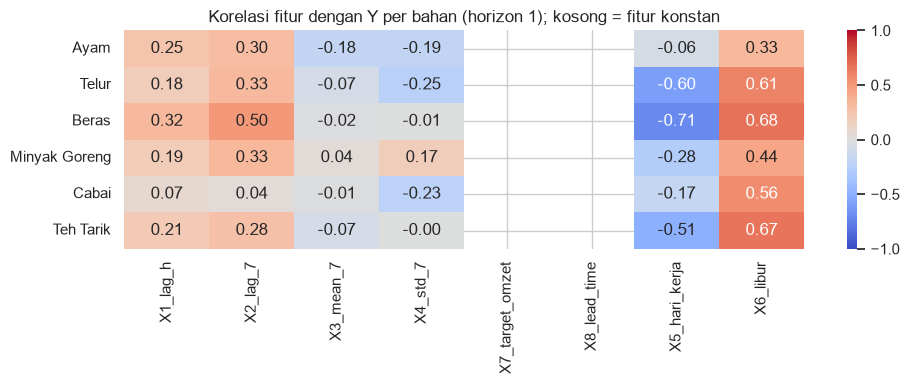

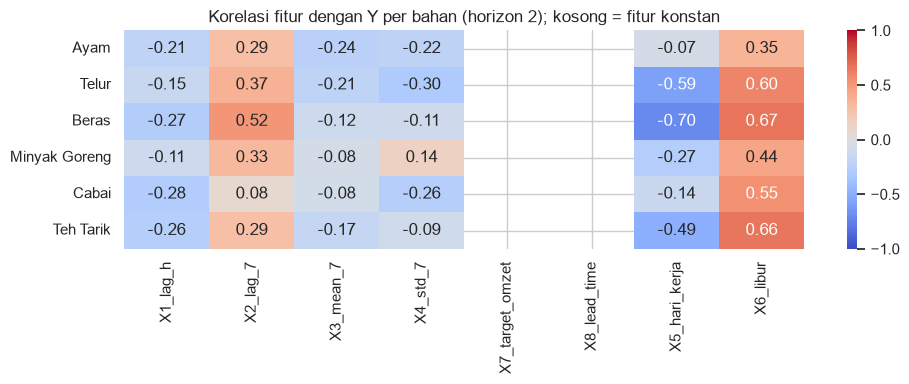

In [15]:
FITUR_KONTINU = ["X1_lag_h", "X2_lag_7", "X3_mean_7", "X4_std_7", "X7_target_omzet", "X8_lead_time"]
FITUR_BINER = ["X5_hari_kerja", "X6_libur"]
FITUR_KATEGORI = ["bahan_baku"]
SEMUA_FITUR = FITUR_KONTINU + FITUR_BINER + FITUR_KATEGORI

for h in HORIZONS:
    sub = dataset[dataset["horizon"] == h]
    peta = {}
    for b in BAHAN_BAKU:
        s = sub[sub["bahan_baku"] == b]
        kolom = [c for c in FITUR_KONTINU + FITUR_BINER if s[c].nunique() > 1]   # fitur konstan dilewati
        peta[b] = s[kolom + ["Y"]].corr()["Y"].drop("Y")
    peta = pd.DataFrame(peta).T.reindex(columns=FITUR_KONTINU + FITUR_BINER)
    plt.figure(figsize=(10, 4))
    sns.heatmap(peta.astype(float), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
    plt.title(f"Korelasi fitur dengan Y per bahan (horizon {h}); kosong = fitur konstan")
    plt.tight_layout(); plt.savefig(f"{FOLDER_OUTPUT}/eda_korelasi_h{h}.png", dpi=130); plt.show()

## 7. Pemisahan data (berdasarkan waktu)
Data **tidak diacak**. Tanggal target paling awal dipakai untuk latih, tanggal target paling akhir untuk uji. Batas tanggal yang sama dipakai untuk semua horizon dan semua bahan.

In [16]:
tanggal_unik = np.sort(dataset["tanggal_target"].unique())
titik = int(round(len(tanggal_unik) * TRAIN_FRAC))
titik = min(max(titik, 1), len(tanggal_unik) - 1)
BATAS_UJI = pd.Timestamp(tanggal_unik[titik])

train = dataset[dataset["tanggal_target"] < BATAS_UJI].copy()
test = dataset[dataset["tanggal_target"] >= BATAS_UJI].copy()
assert train["tanggal_target"].max() < test["tanggal_target"].min()   # tidak ada tumpang tindih waktu

print("Data uji mulai tanggal target:", BATAS_UJI.date())
ringkas_split = pd.DataFrame({
    "latih": train.groupby("horizon").size(),
    "uji": test.groupby("horizon").size(),
    "tgl_target_latih": train.groupby("horizon")["tanggal_target"].agg(lambda s: f"{s.min().date()} s.d. {s.max().date()}"),
    "tgl_target_uji": test.groupby("horizon")["tanggal_target"].agg(lambda s: f"{s.min().date()} s.d. {s.max().date()}"),
})
display(ringkas_split)
if len(test) < 30:
    print("PERHATIAN: data uji sangat sedikit (<30 baris). Hasil hanya uji kelayakan alur, bukan bukti kuat.")

Data uji mulai tanggal target: 2026-05-25


,latih,uji,tgl_target_latih,tgl_target_uji
horizon,,,,
1,101,42,2026-05-08 s.d. 2026-05-24,2026-05-25 s.d. 2026-05-31
2,95,42,2026-05-09 s.d. 2026-05-24,2026-05-25 s.d. 2026-05-31


## 8. Penskalaan fitur
`StandardScaler` hanya untuk fitur kontinu, dan **di-fit pada data latih saja** (di dalam pipeline, sehingga otomatis tidak bocor ke data uji).
Fitur biner dibiarkan, identitas bahan di-one-hot.

In [17]:
def buat_preprocessor():
    return ColumnTransformer([
        ("kontinu", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("skala", StandardScaler())]), FITUR_KONTINU),
        ("biner", "passthrough", FITUR_BINER),
        ("kategori", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FITUR_KATEGORI),
    ])


# Demonstrasi hasil penskalaan pada data latih (horizon pertama)
h0 = HORIZONS[0]
demo_pre = buat_preprocessor().fit(train[train["horizon"] == h0][SEMUA_FITUR])
demo_X = demo_pre.transform(train[train["horizon"] == h0][SEMUA_FITUR])
print("Bentuk matriks fitur setelah penskalaan + one-hot:", demo_X.shape)
display(pd.DataFrame(demo_X, columns=demo_pre.get_feature_names_out()).describe().T[["mean", "std", "min", "max"]].round(2))

Bentuk matriks fitur setelah penskalaan + one-hot: (101, 14)


,mean,std,min,max
kontinu__X1_lag_h,-0.00,1.00,-0.51,3.34
kontinu__X2_lag_7,-0.00,1.00,-0.52,3.32
kontinu__X3_mean_7,0.00,1.00,-0.57,2.51
kontinu__X4_std_7,0.00,1.00,-0.56,2.68
kontinu__X7_target_omzet,0.00,0.00,0.00,0.00
kontinu__X8_lead_time,0.00,0.00,0.00,0.00
biner__X5_hari_kerja,0.64,0.48,0.00,1.00
biner__X6_libur,0.24,0.43,0.00,1.00
kategori__bahan_baku_Ayam,0.17,0.38,0.00,1.00
kategori__bahan_baku_Beras,0.17,0.38,0.00,1.00


## 9. Pemodelan
Kandidat: tiga **baseline** tanpa pelatihan, **Linear Regression**, **Random Forest**, dan **XGBoost** (jika terpasang).
Dua mode: `gabungan` (satu model untuk enam bahan) dan `per_bahan` (satu model tiap bahan).
Hiperparameter ditetapkan tetap (tanpa tuning) karena data sedikit.

In [18]:
def buat_model_dict():
    m = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                               random_state=RANDOM_STATE, n_jobs=-1),
    }
    if ADA_XGB:
        m["XGBoost"] = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                    random_state=RANDOM_STATE, n_jobs=1, verbosity=0)
    return m


BASELINE = {
    "Baseline: Naif (X1)": "X1_lag_h",
    "Baseline: Musiman-7 (X2)": "X2_lag_7",
    "Baseline: Rata-rata 7 hari (X3)": "X3_mean_7",
}
BASELINE_UTAMA = "Baseline: Rata-rata 7 hari (X3)"

prediksi_list = []
model_terlatih = {}   # untuk analisis importance & prediksi akhir


def simpan_prediksi(uji, pred, nama, mode, h):
    prediksi_list.append(pd.DataFrame({
        "horizon": h, "model": nama, "mode": mode,
        "tanggal_target": uji["tanggal_target"].values, "bahan_baku": uji["bahan_baku"].values,
        "aktual": uji["Y"].values, "prediksi": np.clip(np.asarray(pred, dtype=float), 0, None),
    }))


for h in HORIZONS:
    tr = train[train["horizon"] == h]
    te = test[test["horizon"] == h]
    if tr.empty or te.empty:
        print(f"Horizon {h}: data latih/uji kosong, dilewati.")
        continue

    for nama, kolom in BASELINE.items():                       # baseline
        simpan_prediksi(te, te[kolom].values, nama, "-", h)

    for nama, model in buat_model_dict().items():              # model ML
        for mode in MODE_PEMODELAN:
            if mode == "gabungan":
                pipa = Pipeline([("pre", buat_preprocessor()), ("model", model)])
                pipa.fit(tr[SEMUA_FITUR], tr["Y"])
                simpan_prediksi(te, pipa.predict(te[SEMUA_FITUR]), nama, mode, h)
                model_terlatih[(nama, mode, h)] = pipa
            else:
                bagian = []
                for b in BAHAN_BAKU:
                    trb, teb = tr[tr["bahan_baku"] == b], te[te["bahan_baku"] == b]
                    if len(trb) < 5 or teb.empty:
                        continue
                    pipa = Pipeline([("pre", buat_preprocessor()), ("model", clone(model))])
                    pipa.fit(trb[SEMUA_FITUR], trb["Y"])
                    p = pipa.predict(teb[SEMUA_FITUR])
                    bagian.append((teb, p))
                    model_terlatih[(nama, mode, h, b)] = pipa
                if bagian:
                    simpan_prediksi(pd.concat([x[0] for x in bagian]),
                                    np.concatenate([x[1] for x in bagian]), nama, mode, h)

prediksi = pd.concat(prediksi_list, ignore_index=True)
prediksi["nama_lengkap"] = np.where(prediksi["mode"] == "-", prediksi["model"],
                                    prediksi["model"] + " (" + prediksi["mode"] + ")")
print("Total baris prediksi uji:", len(prediksi))
print("Model yang dievaluasi:", sorted(prediksi["nama_lengkap"].unique()))

Total baris prediksi uji: 756
Model yang dievaluasi: ['Baseline: Musiman-7 (X2)', 'Baseline: Naif (X1)', 'Baseline: Rata-rata 7 hari (X3)', 'Linear Regression (gabungan)', 'Linear Regression (per_bahan)', 'Random Forest (gabungan)', 'Random Forest (per_bahan)', 'XGBoost (gabungan)', 'XGBoost (per_bahan)']


## 10. Evaluasi
Metrik: **MAE** (rata-rata selisih absolut), **RMSE** (menghukum kesalahan besar), **WAPE** (total selisih absolut dibagi total penggunaan aktual, dalam %, aman terhadap nilai nol).
Model ML layak dipertimbangkan hanya jika **mengalahkan baseline** secara konsisten.

== Metrik global (semua bahan digabung). MAE/RMSE berada pada satuan campuran, gunakan WAPE sebagai pembanding lintas bahan ==


,horizon,nama_lengkap,n,MAE,RMSE,WAPE_%
0,1,Random Forest (per_bahan),42,467.848,967.532,10.291
1,1,XGBoost (per_bahan),42,705.703,1281.245,15.523
2,1,Linear Regression (per_bahan),42,804.612,1480.957,17.699
3,1,Random Forest (gabungan),42,852.444,1842.326,18.751
4,1,Baseline: Musiman-7 (X2),42,1046.179,2545.499,23.013
5,1,XGBoost (gabungan),42,1203.712,2662.545,26.478
6,1,Baseline: Rata-rata 7 hari (X3),42,1225.757,2710.807,26.963
7,1,Baseline: Naif (X1),42,1597.000,3789.183,35.129
8,1,Linear Regression (gabungan),42,2614.740,5047.265,57.516
9,2,Random Forest (per_bahan),42,548.862,1030.416,12.073



== MAE per bahan, horizon 1 ==


bahan_baku,Ayam,Beras,Cabai,Minyak Goreng,Teh Tarik,Telur
nama_lengkap,,,,,,
Baseline: Musiman-7 (X2),12.857,4705.429,104.714,1316.357,91.143,46.571
Baseline: Naif (X1),25.714,7558.857,117.143,1675.714,160.857,43.714
Baseline: Rata-rata 7 hari (X3),13.673,5839.224,80.837,1279.786,99.755,41.265
Linear Regression (gabungan),821.784,10802.345,647.522,1823.896,733.323,859.569
Linear Regression (per_bahan),22.177,2753.878,203.773,1570.506,232.360,44.975
Random Forest (gabungan),18.471,3414.034,81.134,1508.175,53.548,39.303
Random Forest (per_bahan),17.824,1331.610,98.711,1259.271,62.505,37.170
XGBoost (gabungan),47.359,5281.470,94.347,1690.102,54.137,54.854
XGBoost (per_bahan),27.708,2286.363,131.415,1657.318,84.815,46.597


== WAPE (%) per bahan, horizon 1 ==


...

bahan_baku,Ayam,Beras,Cabai,Minyak Goreng,Teh Tarik,Telur
nama_lengkap,,,,,,
Baseline: Musiman-7 (X2),12.857,4705.429,104.714,1316.357,91.143,46.571
Baseline: Naif (X1),22.857,10331.429,126.286,1021.857,197.429,64.143
Baseline: Rata-rata 7 hari (X3),12.245,6019.959,86.694,1240.163,101.184,47.388
Linear Regression (gabungan),945.442,5804.756,861.015,1868.945,987.969,987.666
Linear Regression (per_bahan),25.774,6355.284,80.640,1924.579,206.556,41.063
Random Forest (gabungan),23.085,7702.240,88.713,1252.403,50.360,29.905
Random Forest (per_bahan),25.898,1550.571,133.220,1477.417,72.948,33.115
XGBoost (gabungan),47.409,13198.393,68.435,1743.789,60.891,48.765
XGBoost (per_bahan),31.223,1952.817,150.746,1727.529,117.433,40.246


== WAPE (%) per bahan, horizon 2 ==


bahan_baku,Ayam,Beras,Cabai,Minyak Goreng,Teh Tarik,Telur
nama_lengkap,,,,,,
Baseline: Musiman-7 (X2),40.9,21.6,39.4,27.8,27.6,29.6
Baseline: Naif (X1),72.7,47.5,47.5,21.5,59.8,40.8
Baseline: Rata-rata 7 hari (X3),39.0,27.7,32.6,26.1,30.7,30.1
Linear Regression (gabungan),3008.2,26.7,323.9,39.4,299.4,627.9
Linear Regression (per_bahan),82.0,29.2,30.3,40.6,62.6,26.1
Random Forest (gabungan),73.5,35.4,33.4,26.4,15.3,19.0
Random Forest (per_bahan),82.4,7.1,50.1,31.1,22.1,21.1
XGBoost (gabungan),150.8,60.7,25.7,36.8,18.5,31.0
XGBoost (per_bahan),99.3,9.0,56.7,36.4,35.6,25.6



== Perbandingan model vs baseline rata-rata 7 hari ==
layak_dipertimbangkan = WAPE lebih rendah dari baseline DAN mengalahkan baseline di minimal separuh bahan.


,horizon,model,WAPE_%,WAPE_baseline_%,selisih_WAPE_poin,bahan_lebih_baik_dari_baseline,layak_dipertimbangkan
0,1,Random Forest (per_bahan),10.29,26.96,-16.67,4/6,True
1,1,XGBoost (per_bahan),15.52,26.96,-11.44,2/6,False
2,1,Linear Regression (per_bahan),17.70,26.96,-9.26,1/6,False
3,1,Random Forest (gabungan),18.75,26.96,-8.21,3/6,True
4,1,Baseline: Musiman-7 (X2),23.01,26.96,-3.95,3/6,True
5,1,XGBoost (gabungan),26.48,26.96,-0.48,2/6,False
6,1,Baseline: Naif (X1),35.13,26.96,8.17,0/6,False
7,1,Linear Regression (gabungan),57.52,26.96,30.55,0/6,False
8,2,Random Forest (per_bahan),12.07,27.52,-15.45,3/6,True
9,2,XGBoost (per_bahan),14.74,27.52,-12.79,2/6,False


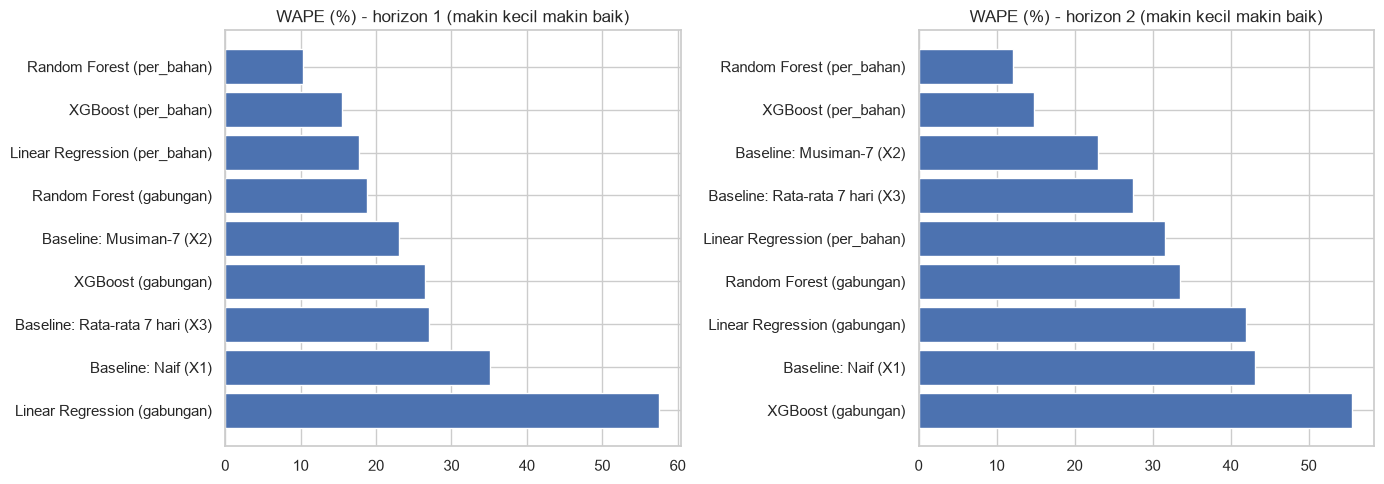

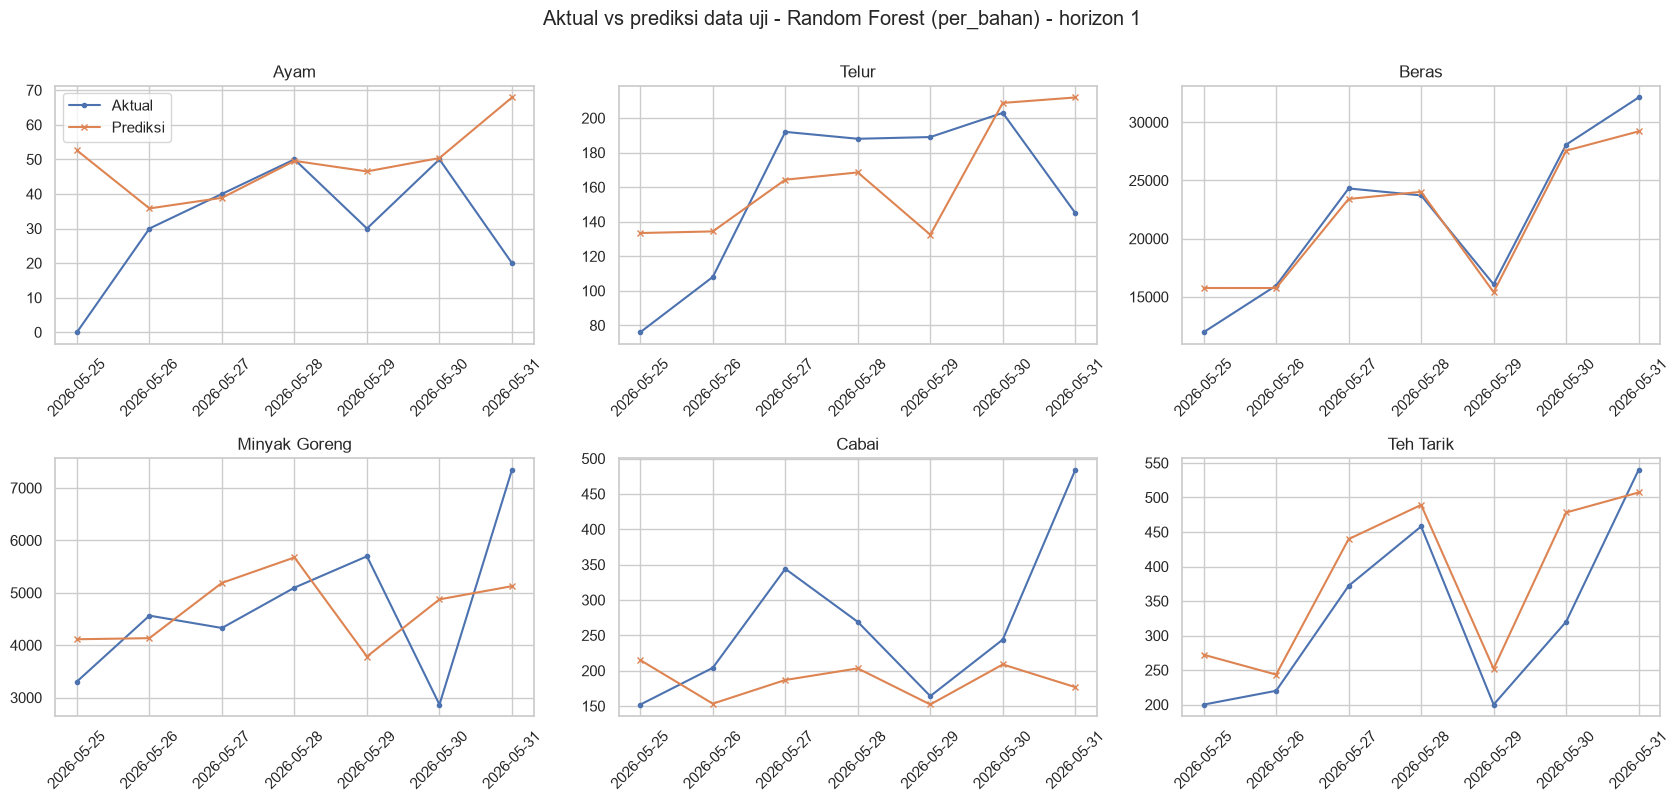

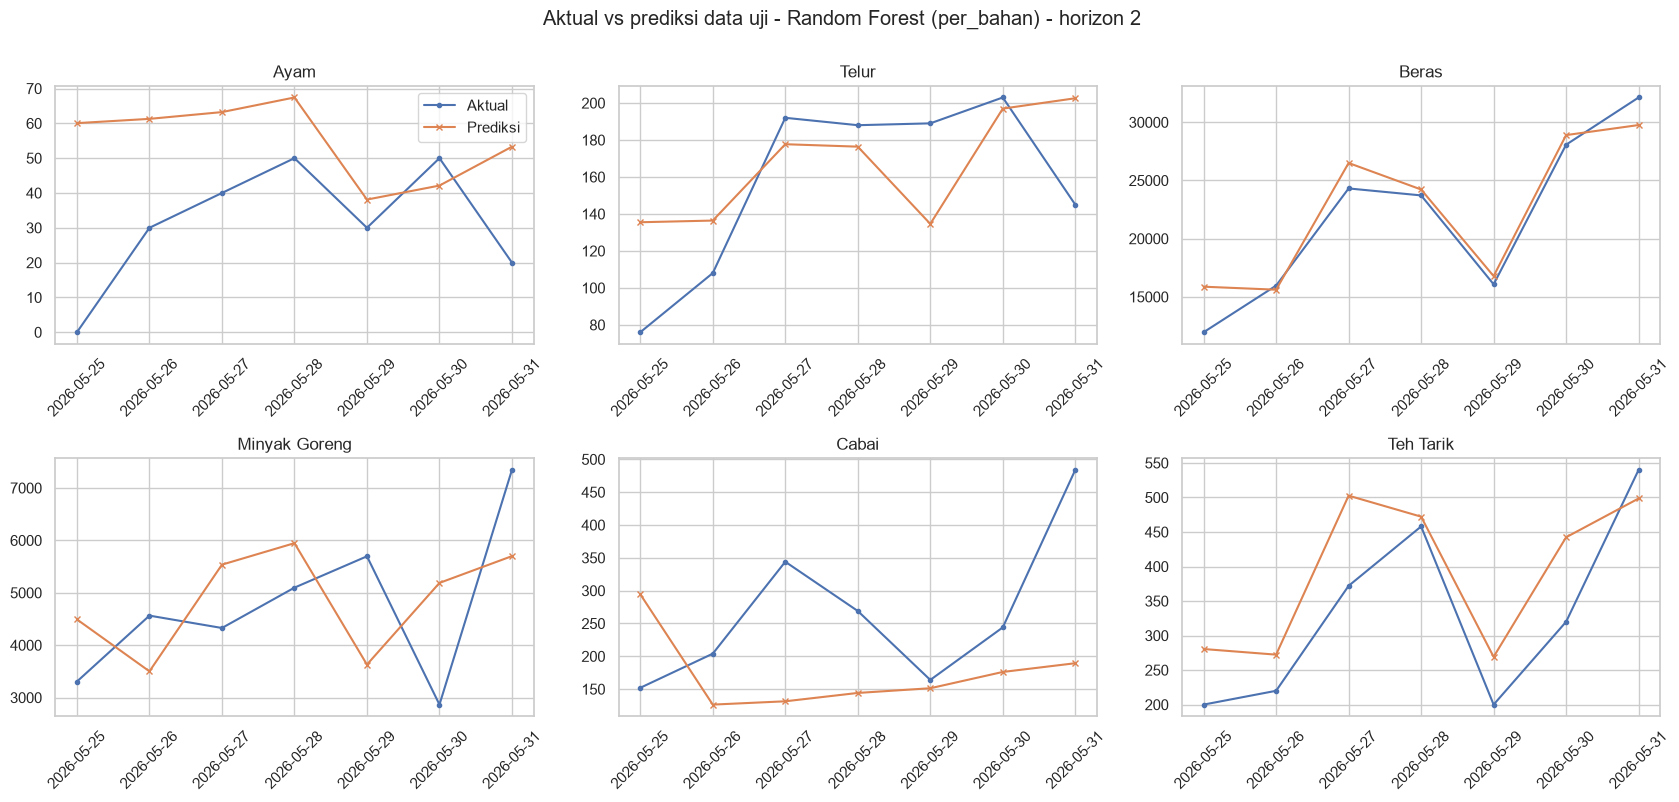

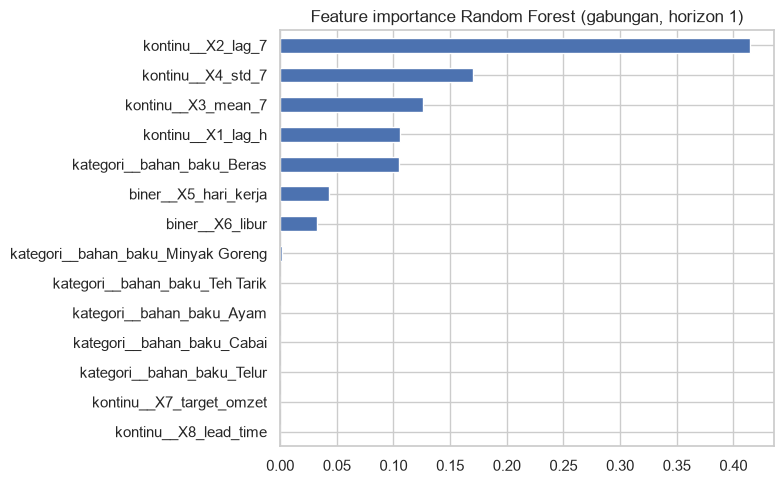

In [19]:
def hitung_metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    mae = mean_absolute_error(y, p)
    rmse = float(np.sqrt(mean_squared_error(y, p)))
    wape = float(np.abs(y - p).sum() / y.sum() * 100) if y.sum() > 0 else np.nan
    return mae, rmse, wape


def tabel_metrik(data, kunci):
    baris = []
    for k, g in data.groupby(kunci):
        k = k if isinstance(k, tuple) else (k,)
        mae, rmse, wape = hitung_metrik(g["aktual"], g["prediksi"])
        baris.append(list(k) + [len(g), mae, rmse, wape])
    return pd.DataFrame(baris, columns=list(kunci) + ["n", "MAE", "RMSE", "WAPE_%"])


# 10.1 Ringkasan global
hasil_global = tabel_metrik(prediksi, ["horizon", "nama_lengkap"]).sort_values(["horizon", "MAE"]).reset_index(drop=True)
print("== Metrik global (semua bahan digabung). MAE/RMSE berada pada satuan campuran, gunakan WAPE sebagai pembanding lintas bahan ==")
display(hasil_global.round(3))

# 10.2 Per bahan
hasil_bahan = tabel_metrik(prediksi, ["horizon", "bahan_baku", "nama_lengkap"])
for h in HORIZONS:
    print(f"\n== MAE per bahan, horizon {h} ==")
    pv = hasil_bahan[hasil_bahan["horizon"] == h].pivot(index="nama_lengkap", columns="bahan_baku", values="MAE")
    display(pv.round(3))
    print(f"== WAPE (%) per bahan, horizon {h} ==")
    pv2 = hasil_bahan[hasil_bahan["horizon"] == h].pivot(index="nama_lengkap", columns="bahan_baku", values="WAPE_%")
    display(pv2.round(1))

# 10.3 Perbandingan terhadap baseline utama
keputusan = []
for h in HORIZONS:
    sub = hasil_bahan[hasil_bahan["horizon"] == h]
    if BASELINE_UTAMA not in set(sub["nama_lengkap"]):
        continue
    base_b = sub[sub["nama_lengkap"] == BASELINE_UTAMA].set_index("bahan_baku")["MAE"]
    base_g = hasil_global[(hasil_global["horizon"] == h) & (hasil_global["nama_lengkap"] == BASELINE_UTAMA)]["WAPE_%"].iloc[0]
    for nama in sub["nama_lengkap"].unique():
        if nama == BASELINE_UTAMA:
            continue
        mb = sub[sub["nama_lengkap"] == nama].set_index("bahan_baku")["MAE"]
        menang = int((mb < base_b.reindex(mb.index)).sum())
        wape = hasil_global[(hasil_global["horizon"] == h) & (hasil_global["nama_lengkap"] == nama)]["WAPE_%"].iloc[0]
        keputusan.append({
            "horizon": h, "model": nama, "WAPE_%": round(wape, 2), "WAPE_baseline_%": round(base_g, 2),
            "selisih_WAPE_poin": round(wape - base_g, 2),
            "bahan_lebih_baik_dari_baseline": f"{menang}/{len(mb)}",
            "layak_dipertimbangkan": bool(wape < base_g and menang >= int(np.ceil(len(mb) / 2))),
        })
keputusan = pd.DataFrame(keputusan).sort_values(["horizon", "WAPE_%"]).reset_index(drop=True)
print("\n== Perbandingan model vs baseline rata-rata 7 hari ==")
print("layak_dipertimbangkan = WAPE lebih rendah dari baseline DAN mengalahkan baseline di minimal separuh bahan.")
display(keputusan)

# 10.4 Grafik MAE/WAPE
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(7 * len(HORIZONS), 5), squeeze=False)
for ax, h in zip(axes[0], HORIZONS):
    s = hasil_global[hasil_global["horizon"] == h].sort_values("WAPE_%")
    ax.barh(s["nama_lengkap"], s["WAPE_%"])
    ax.invert_yaxis(); ax.set_title(f"WAPE (%) - horizon {h} (makin kecil makin baik)")
plt.tight_layout(); plt.savefig(f"{FOLDER_OUTPUT}/evaluasi_wape.png", dpi=130); plt.show()

# 10.5 Aktual vs prediksi model ML terbaik per horizon
for h in HORIZONS:
    kandidat = hasil_global[(hasil_global["horizon"] == h) & (~hasil_global["nama_lengkap"].str.startswith("Baseline"))]
    if kandidat.empty:
        continue
    terbaik = kandidat.sort_values("WAPE_%").iloc[0]["nama_lengkap"]
    sub = prediksi[(prediksi["horizon"] == h) & (prediksi["nama_lengkap"] == terbaik)]
    fig, axes = plt.subplots(2, 3, figsize=(17, 8))
    for ax, b in zip(axes.ravel(), BAHAN_BAKU):
        s = sub[sub["bahan_baku"] == b].sort_values("tanggal_target")
        ax.plot(s["tanggal_target"], s["aktual"], marker="o", ms=3, label="Aktual")
        ax.plot(s["tanggal_target"], s["prediksi"], marker="x", ms=4, label="Prediksi")
        ax.set_title(b); ax.tick_params(axis="x", rotation=45)
    axes[0, 0].legend()
    fig.suptitle(f"Aktual vs prediksi data uji - {terbaik} - horizon {h}", y=1.0)
    plt.tight_layout(); plt.savefig(f"{FOLDER_OUTPUT}/aktual_vs_prediksi_h{h}.png", dpi=130); plt.show()

# 10.6 Pentingnya fitur Random Forest (mode gabungan, horizon pertama)
kunci_rf = ("Random Forest", "gabungan", HORIZONS[0])
if kunci_rf in model_terlatih:
    pipa = model_terlatih[kunci_rf]
    imp = pd.Series(pipa.named_steps["model"].feature_importances_,
                    index=pipa.named_steps["pre"].get_feature_names_out()).sort_values()
    imp.plot(kind="barh", figsize=(8, 5), title=f"Feature importance Random Forest (gabungan, horizon {HORIZONS[0]})")
    plt.tight_layout(); plt.savefig(f"{FOLDER_OUTPUT}/feature_importance_rf.png", dpi=130); plt.show()

## 11. Prediksi besok dan lusa (opsional, untuk tahap prioritas restock)
Model terbaik per horizon (WAPE terendah di antara model ML) dilatih ulang pada **seluruh** data lalu dipakai memprediksi H+1 dan H+2 dari tanggal terakhir pada data.
Hasilnya dapat menjadi input kriteria "kebutuhan mendatang" pada eksperimen SPK.

In [20]:
hasil_akhir = []
for h in HORIZONS:
    kandidat = hasil_global[(hasil_global["horizon"] == h) & (~hasil_global["nama_lengkap"].str.startswith("Baseline"))]
    if kandidat.empty:
        continue
    nama_lengkap = kandidat.sort_values("WAPE_%").iloc[0]["nama_lengkap"]
    nama, mode = re.match(r"^(.*) \((.*)\)$", nama_lengkap).groups()
    semua = dataset[dataset["horizon"] == h]
    baru = bangun_dataset(df_bersih, df_omzet, h, untuk_prediksi=True)
    if baru.empty:
        print(f"Horizon {h}: fitur untuk tanggal terakhir belum lengkap, dilewati.")
        continue
    model_dasar = buat_model_dict()[nama]
    if mode == "gabungan":
        pipa = Pipeline([("pre", buat_preprocessor()), ("model", clone(model_dasar))]).fit(semua[SEMUA_FITUR], semua["Y"])
        p = pipa.predict(baru[SEMUA_FITUR])
        out = baru[["tanggal_asal", "tanggal_target", "bahan_baku", "stok_asal"]].copy()
    else:
        potong = []
        for b in BAHAN_BAKU:
            sb, bb = semua[semua["bahan_baku"] == b], baru[baru["bahan_baku"] == b]
            if len(sb) < 5 or bb.empty:
                continue
            pipa = Pipeline([("pre", buat_preprocessor()), ("model", clone(model_dasar))]).fit(sb[SEMUA_FITUR], sb["Y"])
            o = bb[["tanggal_asal", "tanggal_target", "bahan_baku", "stok_asal"]].copy()
            o["prediksi_penggunaan"] = np.clip(pipa.predict(bb[SEMUA_FITUR]), 0, None)
            potong.append(o)
        out = pd.concat(potong, ignore_index=True)
        p = out.pop("prediksi_penggunaan").values
    out["prediksi_penggunaan"] = np.clip(p, 0, None)
    out["horizon"] = h
    out["model"] = nama_lengkap
    hasil_akhir.append(out)

prediksi_besok_lusa = pd.concat(hasil_akhir, ignore_index=True) if hasil_akhir else pd.DataFrame()
display(prediksi_besok_lusa.round({"prediksi_penggunaan": 2}))

,tanggal_asal,tanggal_target,bahan_baku,stok_asal,prediksi_penggunaan,horizon,model
0,2026-05-31,2026-06-01,Ayam,50,37.64,1,Random Forest (per_bahan)
1,2026-05-31,2026-06-01,Telur,17,180.06,1,Random Forest (per_bahan)
2,2026-05-31,2026-06-01,Beras,54560,27007.46,1,Random Forest (per_bahan)
3,2026-05-31,2026-06-01,Minyak Goreng,38184,4463.34,1,Random Forest (per_bahan)
4,2026-05-31,2026-06-01,Cabai,274,251.39,1,Random Forest (per_bahan)
5,2026-05-31,2026-06-01,Teh Tarik,2701,482.90,1,Random Forest (per_bahan)
6,2026-05-31,2026-06-02,Ayam,50,43.31,2,Random Forest (per_bahan)
7,2026-05-31,2026-06-02,Telur,17,128.71,2,Random Forest (per_bahan)
8,2026-05-31,2026-06-02,Beras,54560,14479.68,2,Random Forest (per_bahan)
9,2026-05-31,2026-06-02,Minyak Goreng,38184,4712.31,2,Random Forest (per_bahan)


## 12. Menyimpan hasil

In [21]:
with pd.ExcelWriter(f"{FOLDER_OUTPUT}/hasil_eksperimen.xlsx", engine="openpyxl") as w:
    dataset.to_excel(w, sheet_name="Dataset_ML", index=False)
    operasionalisasi.to_excel(w, sheet_name="Operasionalisasi", index=False)
    df_bersih.to_excel(w, sheet_name="Data_Bersih", index=False)
    hasil_global.to_excel(w, sheet_name="Metrik_Global", index=False)
    hasil_bahan.to_excel(w, sheet_name="Metrik_PerBahan", index=False)
    keputusan.to_excel(w, sheet_name="Perbandingan_Baseline", index=False)
    prediksi.drop(columns=["nama_lengkap"]).to_excel(w, sheet_name="Prediksi_Uji", index=False)
    prediksi_besok_lusa.to_excel(w, sheet_name="Prediksi_Besok_Lusa", index=False)
print("Selesai. Semua hasil tersimpan di folder:", os.path.abspath(FOLDER_OUTPUT))

Selesai. Semua hasil tersimpan di folder: c:\Users\THINKPAD\New folder\output_eksperimen


## 13. Modul SPK: prioritas restock dengan AHP, SAW, TOPSIS
Tahap ini memakai **hasil prediksi besok & lusa (bagian 11)** untuk meranking bahan baku mana yang paling mendesak di-restock, lalu **membandingkan tiga metode SPK**.
Jalankan setelah sel bagian 11 (`prediksi_besok_lusa`) dan bagian 10 (`hasil_bahan`).

**Alternatif:** 6 bahan baku. **Kriteria** (semuanya *benefit*: makin besar makin mendesak):

| Kode | Kriteria | Definisi | Sumber |
|---|---|---|---|
| C1 | Indeks kebutuhan | Prediksi kebutuhan H+1 + H+2 dibagi (jumlah hari x rata-rata penggunaan historis). Tanpa satuan, sehingga bisa dibandingkan antar bahan | Model prediksi |
| C2 | Defisit stok | max(0, 1 - stok / kebutuhan H+1..H+2). Bagian kebutuhan yang tidak tertutup stok | Stok akhir + prediksi |
| C3 | Lead time | Waktu tunggu pemasok (hari) | `LEAD_TIME_HARI` (asumsi) |
| C4 | Ketidakpastian prediksi | WAPE model terpilih per bahan (rata-rata lintas horizon). Makin tidak pasti, makin perlu penyangga | Evaluasi bagian 10 |

**Metode:**
- **AHP**: bobot kriteria dari perbandingan berpasangan (skala Saaty 1-9, eigenvector, uji konsistensi CR < 0,1). Prioritas alternatif per kriteria juga lewat perbandingan berpasangan (eigenvector), lalu digabung dengan bobot.
- **SAW**: normalisasi linear (x/max), lalu jumlah terbobot.
- **TOPSIS**: normalisasi vektor, jarak ke solusi ideal positif dan negatif, skor kedekatan relatif.

Ketiganya memakai **bobot kriteria yang sama (dari AHP)** agar perbandingan adil: yang dibedakan hanya cara menormalisasi dan menggabungkan nilai.
**Catatan jujur:** bobot AHP berasal dari penilaian (judgment) dan harus disesuaikan dengan penilaian pakar/pemilik usaha. C3 bernilai sama untuk semua bahan, sehingga belum membedakan peringkat sampai data lead time per pemasok tersedia.

### 13.1 Matriks keputusan

In [22]:
# ---------- 13.1 Matriks keputusan: alternatif = 6 bahan baku, kriteria = C1..C4 ----------
# Semua kriteria bersifat BENEFIT (makin besar -> makin mendesak untuk di-restock).
JENIS = {
    "C1_indeks_kebutuhan": "benefit",   # prediksi kebutuhan (H+1 + H+2) dibanding kebutuhan normal (rata-rata historis x jumlah hari)
    "C2_defisit_stok":     "benefit",   # bagian kebutuhan H+1..H+2 yang TIDAK tertutup stok = max(0, 1 - stok/kebutuhan)
    "C3_lead_time":        "benefit",   # lead time pemasok (hari): makin lama, makin awal harus dipesan
    "C4_ketidakpastian":   "benefit",   # WAPE model terpilih per bahan (%): makin tidak pasti, makin perlu penyangga
}
KRITERIA = list(JENIS)

pbl = prediksi_besok_lusa.copy()
pred = pbl.pivot_table(index="bahan_baku", columns="horizon", values="prediksi_penggunaan", aggfunc="first").reindex(BAHAN_BAKU)
pred.columns = [f"prediksi_H{h}" for h in pred.columns]
stok_kini = pbl.drop_duplicates("bahan_baku").set_index("bahan_baku")["stok_asal"].reindex(BAHAN_BAKU).astype(float).clip(lower=0)
rata_hist = df_bersih.groupby("bahan_baku")["penggunaan"].mean().reindex(BAHAN_BAKU)

# WAPE model terpilih (per horizon, per bahan) dari hasil evaluasi, lalu dirata-rata lintas horizon
wape_list = []
for h, nama in pbl.drop_duplicates("horizon").set_index("horizon")["model"].items():
    w_ = hasil_bahan[(hasil_bahan["horizon"] == h) & (hasil_bahan["nama_lengkap"] == nama)].set_index("bahan_baku")["WAPE_%"]
    wape_list.append(w_.reindex(BAHAN_BAKU))
wape_rata = pd.concat(wape_list, axis=1).mean(axis=1)
wape_rata = wape_rata.fillna(wape_rata.mean())

n_hari = pred.shape[1]
kebutuhan = pred.sum(axis=1).clip(lower=1e-9)
rasio_stok = stok_kini / kebutuhan            # = hari cakupan relatif; < 1 berarti stok tidak cukup menutup kebutuhan

tabel_dasar = pred.copy()
tabel_dasar.insert(0, "stok_kini", stok_kini)
tabel_dasar["kebutuhan_total"] = kebutuhan
tabel_dasar["rasio_stok"] = rasio_stok
tabel_dasar["saran_order"] = (kebutuhan - stok_kini).clip(lower=0)   # selisih kekurangan, belum termasuk stok pengaman

X = pd.DataFrame({
    "C1_indeks_kebutuhan": kebutuhan / (n_hari * rata_hist),
    "C2_defisit_stok":     (1 - rasio_stok).clip(lower=0),
    "C3_lead_time":        pd.Series(LEAD_TIME_HARI).reindex(BAHAN_BAKU).astype(float),
    "C4_ketidakpastian":   wape_rata,
}).loc[BAHAN_BAKU]

print("Matriks keputusan (nilai kriteria tiap bahan):")
display(X.round(3))
print("Catatan: C3 bernilai sama untuk semua bahan (lead time masih asumsi), sehingga tidak membedakan peringkat.")

Matriks keputusan (nilai kriteria tiap bahan):


,C1_indeks_kebutuhan,C2_defisit_stok,C3_lead_time,C4_ketidakpastian
Ayam,1.046,0.382,1.0,69.556
Telur,0.991,0.945,1.0,22.343
Beras,0.950,0.000,1.0,6.626
Minyak Goreng,0.986,0.000,1.0,28.847
Cabai,0.961,0.355,1.0,43.620
Teh Tarik,1.000,0.000,1.0,20.523


Catatan: C3 bernilai sama untuk semua bahan (lead time masih asumsi), sehingga tidak membedakan peringkat.


### 13.2 Fungsi AHP, SAW, TOPSIS

In [23]:
# ---------- 13.2 Fungsi AHP, SAW, dan TOPSIS ----------
from itertools import combinations

def _bagi_aman(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=(b != 0))

# ===== AHP =====
RI = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45}   # Random Index Saaty

def ahp_eigen(A):
    """Bobot prioritas = eigenvector utama matriks perbandingan berpasangan; hitung CI dan CR."""
    A = np.asarray(A, float); n = A.shape[0]
    vals, vecs = np.linalg.eig(A)
    i = int(np.argmax(vals.real))
    w = np.abs(vecs[:, i].real); w = w / w.sum()
    lam = float(vals[i].real)
    ci = (lam - n) / (n - 1) if n > 1 else 0.0
    cr = ci / RI[n] if RI.get(n, 0) > 0 else 0.0
    return w, lam, ci, cr

def matriks_dari_nilai(p, bulatkan=True):
    """Bentuk matriks perbandingan alternatif dari nilai data: a_ij = p_i / p_j, dibatasi skala Saaty 1/9..9.
    delta kecil mencegah pembagian nol dan meredam selisih ekstrem. bulatkan=True -> skala Saaty bilangan bulat."""
    p = np.asarray(p, float); n = len(p)
    delta = 0.05 * p.max() if p.max() > 0 else 1.0
    q = p + delta
    A = np.ones((n, n))
    for i in range(n):
        for j in range(n):
            a = float(np.clip(q[i] / q[j], 1 / 9, 9))
            if bulatkan:
                a = float(round(a)) if a >= 1 else 1.0 / round(1.0 / a)
            A[i, j] = a
    return A

def _nilai_preferensi(v, jenis):
    v = np.asarray(v, float)
    if jenis == "cost":
        pos = v[v > 0]
        return 1.0 / np.where(v > 0, v, pos.min() if len(pos) else 1.0)
    return v

def ahp_alternatif(X, w, jenis, bulatkan=True):
    """AHP penuh: prioritas lokal alternatif per kriteria (eigenvector) x bobot kriteria."""
    L = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)
    cr_lokal = {}
    for k in X.columns:
        A = matriks_dari_nilai(_nilai_preferensi(X[k].values, jenis[k]), bulatkan)
        wl, _, _, cr = ahp_eigen(A)
        L[k] = wl; cr_lokal[k] = cr
    return (L * w).sum(axis=1), L, pd.Series(cr_lokal)

# ===== SAW =====
def saw(X, w, jenis):
    """Normalisasi linear: benefit = x/max, cost = min/x. Skor = jumlah (r x bobot)."""
    R = X.astype(float).copy()
    for k in X.columns:
        v = X[k].values.astype(float)
        if jenis[k] == "benefit":
            R[k] = _bagi_aman(v, np.full_like(v, v.max()))
        else:
            mn = v[v > 0].min() if (v > 0).any() else 0.0
            R[k] = np.where(v > 0, _bagi_aman(np.full_like(v, mn), v), 1.0)
    return (R * w).sum(axis=1), R

# ===== TOPSIS =====
def topsis(X, w, jenis):
    """Normalisasi vektor, bobot, solusi ideal positif/negatif, jarak Euclid, skor kedekatan relatif."""
    V = X.astype(float).copy()
    for k in X.columns:
        d = np.sqrt((X[k].astype(float) ** 2).sum())
        V[k] = (X[k] / d if d > 0 else 0.0) * w[k]
    ben = {k: jenis[k] == "benefit" for k in X.columns}
    ip = pd.Series({k: (V[k].max() if ben[k] else V[k].min()) for k in X.columns})
    ineg = pd.Series({k: (V[k].min() if ben[k] else V[k].max()) for k in X.columns})
    d_pos = np.sqrt(((V - ip) ** 2).sum(axis=1))
    d_neg = np.sqrt(((V - ineg) ** 2).sum(axis=1))
    return pd.Series(_bagi_aman(d_neg, d_pos + d_neg), index=X.index), d_pos, d_neg

def skor_semua(Xs, ws):
    return {"AHP": ahp_alternatif(Xs, ws, JENIS)[0],
            "SAW": saw(Xs, ws, JENIS)[0],
            "TOPSIS": topsis(Xs, ws, JENIS)[0]}

### 13.3 Bobot kriteria (AHP)

In [24]:
# ---------- 13.3 Bobot kriteria dengan AHP (perbandingan berpasangan, skala Saaty 1-9) ----------
# Urutan baris/kolom = C1, C2, C3, C4. a_ij > 1 berarti kriteria baris lebih penting daripada kolom.
# ASUMSI PENILAI: defisit stok paling menentukan urgensi restock. Ganti angka berikut sesuai penilaian pakar/pemilik usaha.
A_KRITERIA = np.array([
    #  C1     C2     C3     C4
    [1.0,   1/3,   2.0,   2.0],   # C1 indeks kebutuhan
    [3.0,   1.0,   5.0,   4.0],   # C2 defisit stok
    [1/2,   1/5,   1.0,   1/2],   # C3 lead time
    [1/2,   1/4,   2.0,   1.0],   # C4 ketidakpastian prediksi
])
w_arr, lam_maks, CI, CR = ahp_eigen(A_KRITERIA)
bobot = pd.Series(w_arr, index=KRITERIA)
print("Bobot kriteria hasil AHP:")
display(bobot.round(4).to_frame("bobot"))
print(f"lambda_maks = {lam_maks:.4f} | CI = {CI:.4f} | CR = {CR:.4f} ->",
      "KONSISTEN (CR < 0,1)" if CR < 0.1 else "TIDAK KONSISTEN (CR >= 0,1): perbaiki penilaian perbandingan berpasangan")

Bobot kriteria hasil AHP:


,bobot
C1_indeks_kebutuhan,0.2143
C2_defisit_stok,0.5498
C3_lead_time,0.0942
C4_ketidakpastian,0.1417


lambda_maks = 4.0566 | CI = 0.0189 | CR = 0.0210 -> KONSISTEN (CR < 0,1)


### 13.4 Ranking prioritas restock

In [25]:
# ---------- 13.4 Ranking prioritas restock dengan tiga metode ----------
skor_ahp, L_ahp, cr_lokal = ahp_alternatif(X, bobot, JENIS)
skor_saw, R_saw = saw(X, bobot, JENIS)
skor_topsis, d_pos, d_neg = topsis(X, bobot, JENIS)
skor_dasar = {"AHP": skor_ahp, "SAW": skor_saw, "TOPSIS": skor_topsis}
METODE = list(skor_dasar)

ranking = pd.DataFrame({f"{m}_skor": s for m, s in skor_dasar.items()})
for m in METODE:
    ranking[f"{m}_rank"] = skor_dasar[m].rank(ascending=False, method="min").astype(int)
ranking["rata2_rank"] = ranking[[f"{m}_rank" for m in METODE]].mean(axis=1)
hasil_spk = tabel_dasar.join(ranking).sort_values(["rata2_rank", "TOPSIS_rank"])

print("CR lokal AHP per kriteria (perbandingan alternatif):", cr_lokal.round(3).to_dict())
print("\nRanking prioritas restock (1 = paling prioritas):")
display(hasil_spk[["stok_kini", "kebutuhan_total", "rasio_stok", "saran_order"]
                  + [f"{m}_rank" for m in METODE] + [f"{m}_skor" for m in METODE]].round(3))

CR lokal AHP per kriteria (perbandingan alternatif): {'C1_indeks_kebutuhan': 0.0, 'C2_defisit_stok': 0.013, 'C3_lead_time': 0.0, 'C4_ketidakpastian': 0.011}

Ranking prioritas restock (1 = paling prioritas):


,stok_kini,kebutuhan_total,rasio_stok,saran_order,AHP_rank,SAW_rank,TOPSIS_rank,AHP_skor,SAW_skor,TOPSIS_skor
bahan_baku,,,,,,,,,,
Telur,17.0,308.764,0.055,291.764,1,1,1,0.277,0.893,0.869
Ayam,50.0,80.956,0.618,30.956,2,2,2,0.245,0.673,0.432
Cabai,274.0,425.005,0.645,151.005,3,3,3,0.225,0.587,0.385
Minyak Goreng,38184.0,9175.654,4.161,0.000,4,4,4,0.091,0.355,0.066
Teh Tarik,2701.0,679.642,3.974,0.000,5,5,5,0.086,0.341,0.043
Beras,54560.0,41487.145,1.315,0.000,6,6,6,0.076,0.302,0.000


### 13.5 Membandingan metode SPK
Empat pemeriksaan: (a) kesepakatan peringkat antar metode, (b) kesesuaian dengan acuan operasional (urutan rasio stok terhadap kebutuhan), (c) stabilitas peringkat bila bobot diganggu (simulasi Dirichlet), (d) *rank reversal* (apakah urutan berubah bila satu alternatif dihapus). Hasilnya diringkas menjadi rata-rata peringkat indikator untuk menyarankan metode.

In [26]:
# ---------- 13.5 Perbandingan metode ----------
def spearman(a, b):
    r = pd.Series(np.asarray(a, float)).rank().corr(pd.Series(np.asarray(b, float)).rank())
    return 0.0 if pd.isna(r) else float(r)

def kendall(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float); n = len(a)
    s = sum(np.sign(a[i] - a[j]) * np.sign(b[i] - b[j]) for i, j in combinations(range(n), 2))
    return s / (n * (n - 1) / 2)

# (a) Kesepakatan antar metode (korelasi peringkat)
sp = pd.DataFrame({m1: {m2: spearman(skor_dasar[m1], skor_dasar[m2]) for m2 in METODE} for m1 in METODE})
kd = pd.DataFrame({m1: {m2: kendall(skor_dasar[m1], skor_dasar[m2]) for m2 in METODE} for m1 in METODE})
print("(a) Korelasi peringkat Spearman antar metode:"); display(sp.round(3))
print("    Kendall tau antar metode:"); display(kd.round(3))

# (b) Kesesuaian dengan acuan operasional: urutan 'rasio stok terhadap kebutuhan' (makin kecil makin mendesak).
#     Ini sanity check, bukan kebenaran mutlak (C2 yang berbobot terbesar memang turunan dari rasio stok).
acuan = -rasio_stok
kesesuaian = {m: spearman(skor_dasar[m], acuan) for m in METODE}

# (c) Stabilitas ranking saat bobot AHP diganggu (simulasi Dirichlet di sekitar bobot dasar)
N_SIM, KONSENTRASI = 1000, 30
rng = np.random.default_rng(RANDOM_STATE)
stab = {m: [] for m in METODE}; top1 = {m: 0 for m in METODE}; top3_sama = {m: 0 for m in METODE}
dasar_top1 = {m: skor_dasar[m].idxmax() for m in METODE}
dasar_top3 = {m: set(skor_dasar[m].nlargest(3).index) for m in METODE}
for _ in range(N_SIM):
    ws = pd.Series(rng.dirichlet(bobot.values * KONSENTRASI + 1e-6), index=KRITERIA)
    sk = skor_semua(X, ws)
    for m in METODE:
        stab[m].append(spearman(sk[m], skor_dasar[m]))
        top1[m] += int(sk[m].idxmax() == dasar_top1[m])
        top3_sama[m] += int(set(sk[m].nlargest(3).index) == dasar_top3[m])

# (d) Rank reversal: hapus satu alternatif, lihat apakah urutan relatif sisanya terbalik (hanya pembalikan tegas dihitung)
def persen_rank_reversal(m):
    balik = pasangan = 0
    for alt in X.index:
        sisa = X.drop(index=alt)
        s = skor_semua(sisa, bobot)[m]
        for i, j in combinations(sisa.index, 2):
            pasangan += 1
            balik += int(np.sign(skor_dasar[m][i] - skor_dasar[m][j]) * np.sign(s[i] - s[j]) < 0)
    return balik / pasangan * 100

evaluasi = pd.DataFrame({
    "korelasi_dgn_metode_lain": {m: np.mean([sp.loc[m, o] for o in METODE if o != m]) for m in METODE},
    "kesesuaian_acuan_spearman": kesesuaian,
    "stabilitas_bobot_spearman": {m: float(np.mean(stab[m])) for m in METODE},
    "top1_tetap_%": {m: top1[m] / N_SIM * 100 for m in METODE},
    "top3_tetap_%": {m: top3_sama[m] / N_SIM * 100 for m in METODE},
    "rank_reversal_%": {m: persen_rank_reversal(m) for m in METODE},
})
print(f"(b)-(d) Evaluasi metode (simulasi bobot N={N_SIM}):")
display(evaluasi.round(3))

# (e) Rekomendasi: peringkat tiap indikator (1 = terbaik), lalu rata-rata
indikator_naik = ["kesesuaian_acuan_spearman", "stabilitas_bobot_spearman", "top1_tetap_%", "top3_tetap_%"]
rk = pd.concat([evaluasi[indikator_naik].rank(ascending=False, method="min"),
                evaluasi[["rank_reversal_%"]].rank(ascending=True, method="min")], axis=1)
evaluasi["rata2_peringkat_indikator"] = rk.mean(axis=1)
terbaik = evaluasi["rata2_peringkat_indikator"][evaluasi["rata2_peringkat_indikator"] == evaluasi["rata2_peringkat_indikator"].min()].index.tolist()
print("Rata-rata peringkat indikator (makin kecil makin baik):", evaluasi["rata2_peringkat_indikator"].round(2).to_dict())
print("Metode paling unggul pada data ini:", ", ".join(terbaik))
print("PERHATIAN: hanya 6 alternatif dan 4 kriteria (C3 konstan). Tanpa data kebenaran (stockout sebenarnya), "
      "perbandingan ini menilai konsistensi & kestabilan metode, bukan akurasi mutlak.")

(a) Korelasi peringkat Spearman antar metode:


,AHP,SAW,TOPSIS
AHP,1.0,1.0,1.0
SAW,1.0,1.0,1.0
TOPSIS,1.0,1.0,1.0


    Kendall tau antar metode:


,AHP,SAW,TOPSIS
AHP,1.0,1.0,1.0
SAW,1.0,1.0,1.0
TOPSIS,1.0,1.0,1.0


(b)-(d) Evaluasi metode (simulasi bobot N=1000):


,korelasi_dgn_metode_lain,kesesuaian_acuan_spearman,stabilitas_bobot_spearman,top1_tetap_%,top3_tetap_%,rank_reversal_%
AHP,1.0,0.771,0.996,92.8,100.0,0.0
SAW,1.0,0.771,1.000,99.6,100.0,0.0
TOPSIS,1.0,0.771,1.000,99.9,100.0,0.0


Rata-rata peringkat indikator (makin kecil makin baik): {'AHP': 1.8, 'SAW': 1.4, 'TOPSIS': 1.0}
Metode paling unggul pada data ini: TOPSIS
PERHATIAN: hanya 6 alternatif dan 4 kriteria (C3 konstan). Tanpa data kebenaran (stockout sebenarnya), perbandingan ini menilai konsistensi & kestabilan metode, bukan akurasi mutlak.


### 13.6 Visualisasi

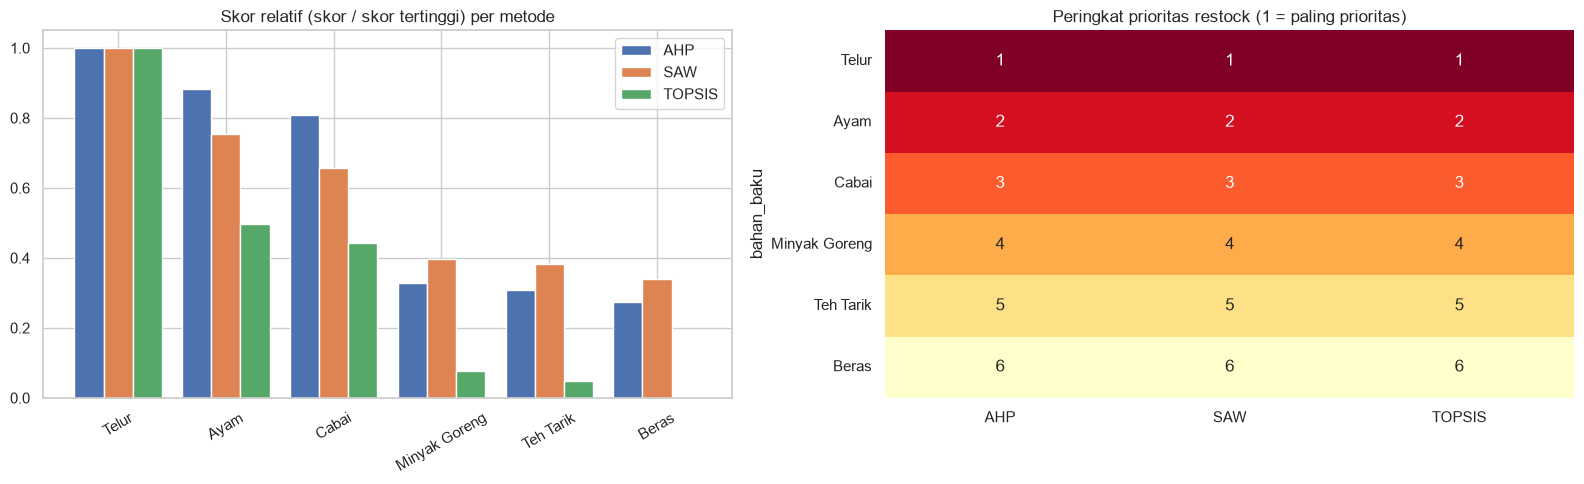

In [27]:
# ---------- 13.6 Visualisasi ----------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
urut = hasil_spk.index.tolist()
lebar = 0.27
for i, m in enumerate(METODE):
    s = skor_dasar[m].reindex(urut)
    axes[0].bar(np.arange(len(urut)) + (i - 1) * lebar, s / s.max(), width=lebar, label=m)
axes[0].set_xticks(range(len(urut))); axes[0].set_xticklabels(urut, rotation=30)
axes[0].set_title("Skor relatif (skor / skor tertinggi) per metode"); axes[0].legend()
sns.heatmap(hasil_spk[[f"{m}_rank" for m in METODE]].rename(columns=lambda c: c.replace("_rank", "")),
            annot=True, fmt="d", cmap="YlOrRd_r", cbar=False, ax=axes[1])
axes[1].set_title("Peringkat prioritas restock (1 = paling prioritas)")
plt.tight_layout(); plt.savefig(f"{FOLDER_OUTPUT}/spk_perbandingan.png", dpi=130); plt.show()

### 13.7 Menyimpan hasil SPK

In [28]:
# ---------- 13.7 Menyimpan hasil SPK ----------
path_xlsx = f"{FOLDER_OUTPUT}/hasil_eksperimen.xlsx"
kw = dict(mode="a", if_sheet_exists="replace") if os.path.exists(path_xlsx) else dict(mode="w")
with pd.ExcelWriter(path_xlsx, engine="openpyxl", **kw) as w_:
    X.to_excel(w_, sheet_name="SPK_Matriks_Keputusan")
    bobot.to_frame("bobot_AHP").to_excel(w_, sheet_name="SPK_Bobot_AHP")
    hasil_spk.to_excel(w_, sheet_name="SPK_Ranking_Restock")
    evaluasi.to_excel(w_, sheet_name="SPK_Evaluasi_Metode")
print("Hasil SPK tersimpan di:", os.path.abspath(path_xlsx))

Hasil SPK tersimpan di: c:\Users\THINKPAD\New folder\output_eksperimen\hasil_eksperimen.xlsx
